# 面向长对话的贝叶斯自适应上下文选择
**ARIN7101 · M1–M4正式实验 + M5结果可视化 · v5.1 · 2026-11-05**

研究问题：在受控合成长对话中，问题特征能否帮助 Thompson Sampling 选择兼顾正确率与输入长度的上下文？

本版补全数据、策略、后验核查、冻结、正式评估及统计交接。默认运行 **formal：60条对话、18,000题**；固定测试种子 `20261105`，开发种子 `130000`。M5现已新增七张正式结果图和评价；slides/视频仍由小组后续制作。

**阅读路线：** [M1 数据](#member-m1) → [M2 策略](#member-m2) → [M3 方法](#member-m3) → [M4 统计](#member-m4)。从空内核必须按顺序 Run All。

本工作本是**规则回答器上的模拟研究**，不是实际LLM实验。已有v2/v3/v4演示被查看；本轮在新测试数据生成前冻结，不声称外部预注册。AI执行与样例复核有明确署名，不能当作小组成员亲自完成的人工审核。最终课程提交仍由小组完成。

修改前副本：`archive/ARIN7101_Context_Bandit_Team_Notebook.before_M1_M4_20261105_145152.ipynb`。旧计划书保留，执行与交接规则以本v5及README为准。

**新增M5：** 可从空内核直接运行[M5](#member-m5)，读取已归档的正式结果。M1–M4既有输出保留为历史执行证据；M5另有独立清单，原冻结归档不改写。

## 0 · 环境、资源和重跑方式
终端在项目目录运行：
```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python scripts/run_notebook.py --mode formal
# 交互使用：python -m jupyter lab
```
Windows激活：`.venv\Scripts\activate`。实际验证Python和包版本见输出 `manifest.json`；复用本机版本可安装 `requirements-tested.txt`。

仅重绘结果可执行 `python scripts/run_notebook.py --section m5`，无需重跑模拟。

主线**无需GPU、外部数据、模型权重、API或联网**；开发/测试数据由下面的公开生成器生成并归档。已补齐资源包：`resources/public/` 方法教程、`resources/course/` 本地课程原件、`resources/resource_manifest.json` 来源与SHA256。公开阅读资料可用 `python scripts/download_resources.py` 重下；课程资料从Moodle获取或传入 `--course-dir`，不假装存在公开下载链接。

默认formal可直接Run All。终端 `--mode demo` 运行6条/场景的烟雾检查，输出用 `--output validation/m1_m4/demo_executed.ipynb` 保存。正式主种子不随重跑变化；已有目录时创建带时间戳的复现目录，保留旧结果，**重复同一批数据不增加样本量**。运行失败也保留目录和日志。算法和数据输出每条对话落盘，便于定位故障。

资源来源：[Thompson Sampling作者教程](https://web.stanford.edu/~bvr/pubs/TS_Tutorial_FnT.pdf)、[TF–IDF官方接口](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)、[SciPy BFGS官方接口](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-bfgs.html)。下载材料只用于理解方法，不参与拟合或评价。

In [1]:
import os, re, json, hashlib, time, platform, textwrap, gzip, shutil, sys
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path
from functools import lru_cache
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
from scipy.special import expit
from scipy.optimize import minimize
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

NOTEBOOK_PATH = Path('ARIN7101_Context_Bandit_Team_Notebook.ipynb')
assert NOTEBOOK_PATH.is_file(), '内核工作目录必须是Final_Project；请从项目目录启动Jupyter。'
MODE = os.environ.get('ARIN_MODE', 'formal')
FINAL_SEED = 20261105  # 在本次正式数据生成前固定，不按效果换seed
RUN_M5 = False        # 用户要求本轮不做M5
RUN_BACKUP = False
assert MODE in ['demo', 'formal']
CFG = dict(version='v5-m1-m4', T=300, n_dev=3, n_eval=6 if MODE=='demo' else 30,
           u=.25, q=.02, pA=.90, pB=.10, conflict_fraction=.25, lam=.5, cref=512,
           gamma_grid=[.9,.97,.995,1.], dev_seed=130000,
           eval_seed=730000 if MODE=='demo' else FINAL_SEED,
           algorithm_seeds=[17,37], bootstrap_seed=2026, nboot=2000, refit_every=5,
           prior_precision=1., feature_names=['intercept','explicit_project','its'],
           budgets={'recent_short':128,'recent_long':512,'tfidf':256,'resolved_tfidf':256})
SCENARIOS = ['stable','abrupt']; ARMS = list(CFG['budgets'])
BASE_OUT = Path('arin7101_team_outputs') / ('demo_m1_m4' if MODE=='demo' else f'formal_m1_m4_{FINAL_SEED}')
STAMP = datetime.now(ZoneInfo('Asia/Hong_Kong')).strftime('%Y%m%d_%H%M%S_%f')
OUT = BASE_OUT if not BASE_OUT.exists() else BASE_OUT.with_name(BASE_OUT.name+'_reproduction_'+STAMP)
OUT.mkdir(parents=True, exist_ok=False)
(OUT/'checkpoints').mkdir()
TEAM_DIR = Path('team_workspace'); TEAM_DIR.mkdir(exist_ok=True)
SYSTEM = 'Answer the current value using the context. Later statements override earlier ones. Resolve its using the latest focus. Return JSON {"value":"..."}; use UNKNOWN if unsupported.'
@lru_cache(maxsize=50000)
def units(s): return len(re.findall(r'\w+|[^\w\s]',s))
def prompt(q,ctx): return SYSTEM+'\nContext:\n'+'\n'.join(m['text'] for m in ctx)+'\nQuestion: '+q
def digest_file(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def save_json(name, value):
    (OUT/name).write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
source_document = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
CODE_TEXT = '\n\n'.join(''.join(c['source']) for c in source_document['cells'] if c['cell_type']=='code')
CODE_HASH = hashlib.sha256(CODE_TEXT.encode()).hexdigest()
for c in source_document['cells']:
    if c['cell_type']=='code': c['outputs']=[]; c['execution_count']=None
save_json('notebook_snapshot.ipynb',source_document)
START = time.perf_counter()
CHECKS = {}
for source in ['requirements.txt','requirements-tested.txt','resources/resource_manifest.json']:
    if Path(source).exists(): shutil.copy2(source,OUT/Path(source).name)
print('Mode:',MODE,'| regex proxy units, NOT LLM tokens | Output:',OUT.resolve())
print('No external data/model download is required. M5 disabled:',not RUN_M5)

Mode: formal | regex proxy units, NOT LLM tokens | Output: /Users/hjc0401/Desktop/HKU/project/Final_Project/arin7101_team_outputs/formal_m1_m4_20261105
No external data/model download is required. M5 disabled: True


<a id="member-m1"></a>
## M1 · 数据、问题定义与可回查审计
**交付：** 数据字典、全部生成数据、独立真值核查、10题证据链、AI复核记录、供真人交叉检查的表格。

6个项目×4个属性（dataset/language/metric/deadline）；初始化25%的项目–属性组合有多版本，每轮加入focus、事实、干扰，事实以0.25概率更新。每条300题。stable中近期题概率全程0.9；abrupt在`t=150`起从0.9变为0.1。改变的是问题分布，答案规则不变。

近期题的its指向当前focus，询问本轮事实；历史题显式指定非当前focus的项目。问题本身不含真值。10个初始版本和同义表达是计划书预设的检索压力机制，**不能把它当自然对话分布**；特征几乎直接标识题型，手写RuleRouter应作为重要参照。

| 数据字段 | 可见范围 | 定义 |
|---|---|---|
| history[id,text]、question | 上下文构造器 | 仅取`history[:end]`；id是时间顺序 |
| question、四臂cost | 学习器choose | 不含场景、gold、标签或未选奖励 |
| selected arm、y、question | 学习器update | 只接收所选臂0/1反馈 |
| gold、evidence、old_values | 评估器 | 最新有效值、最近一次记录、过期值集合 |
| qtype、state、scenario | 评估器/描述统计 | 不传入choose/update |
| seed、t、end | 追溯 | 对话种子、0起始轮次、历史截断位置 |

**独立审计原则：** 第二个解析器从原始文本重建focus与事实，不调用`target/parse_fact/normalize`，检查每题gold、最新证据和旧值集合。仍只能发现实现不一致，不能证明模板具有现实代表性。

In [2]:
ALIASES={'dataset':'data source','language':'coding language','metric':'evaluation measure','deadline':'due date'}
ATTRS=list(ALIASES)
BOILER='Please use this setting in subsequent work and keep other project requirements unchanged.'
def normalize(s):
    for a,b in ALIASES.items(): s=s.replace(b,a)
    return s
FACT=re.compile(r'project (P\d+): the (dataset|language|metric|deadline) is (V\d+)')
FOCUS=re.compile(r'Focus is project (P\d+)')
def parse_fact(text):
    m=FACT.search(normalize(text)); return m.groups() if m else None
def target(q,ctx):
    p=re.search(r'P\d+',q)
    if p: project=p.group()
    else:
        f=[FOCUS.search(m['text']).group(1) for m in ctx if FOCUS.search(m['text'])]
        project=f[-1] if f else None
    qn=normalize(q); attr=next((a for a in ATTRS if re.search(r'\b'+a+r'\b',qn)),None)
    return project,attr

def generate(seed,scenario,T=None,conflict_fraction=None,explicit_recent=False,no_synonyms=False):
    rng=np.random.default_rng(seed); T=T or CFG['T']; hist=[]; truth={}; versions={}; latest={}; probes=[]
    projects=[f'P{seed*10+i}' for i in range(6)]; serial=0
    def append(text): hist.append({'id':len(hist),'text':text}); return len(hist)-1
    def fact(p,a,alias=False,new=True):
        nonlocal serial
        if new:
            serial+=1; v=f'V{seed*100000+serial}'; truth[p,a]=v; versions.setdefault((p,a),[]).append(v)
        else:v=truth[p,a]
        name=ALIASES[a] if alias and not no_synonyms else a
        latest[p,a]=append(f'For project {p}: the {name} is {v}. '+BOILER)
    cf=CFG['conflict_fraction'] if conflict_fraction is None else conflict_fraction
    for p in projects:
        for a in ATTRS:
            conflict=rng.random()<cf
            for _ in range(9 if conflict else 1):fact(p,a)
            if conflict:fact(p,a,alias=True)
    state=0
    for t in range(T):
        if scenario=='abrupt':state=int(t>=T//2)
        elif scenario=='markov' and t>0 and rng.random()<CFG['q']:state=1-state
        p=str(rng.choice(projects)); a=str(rng.choice(ATTRS))
        append(f'Focus is project {p}. We are reviewing its latest requirements.')
        fact(p,a,alias=True,new=rng.random()<CFG['u'])
        append('The next meeting will review progress and remaining questions.')
        recent=rng.random()<(CFG['pA'] if state==0 else CFG['pB'])
        qp=p if recent else str(rng.choice([z for z in projects if z!=p]))
        qa=a if recent else str(rng.choice(ATTRS))
        term=ALIASES[qa] if recent and not no_synonyms else qa
        ref=qp if not recent or explicit_recent else 'its'
        q=f'What is {ref} current {term}?'
        probes.append(dict(t=t,question=q,end=len(hist),gold=truth[qp,qa],
                           evidence=latest[qp,qa],old_values=versions[qp,qa][:-1].copy(),
                           qtype='recent' if recent else 'historical',state='A' if state==0 else 'B'))
    return dict(seed=seed,scenario=scenario,history=hist,probes=probes)
def public_view(ep,probe):
    return {'question':probe['question'],'history':ep['history'][:probe['end']]}

DEV=[generate(CFG['dev_seed']+100*s+i,sc) for s,sc in enumerate(SCENARIOS) for i in range(CFG['n_dev'])]
print('Development:',len(DEV),'dialogues;',CFG['T'],'questions/dialogue')

Development: 6 dialogues; 300 questions/dialogue


In [3]:
# 与回答器独立实现的文本审计；避免用同一个函数同时生成“答案”和“证明”。
def independent_trace(question, history):
    explicit = re.search(r'\bP[0-9]+\b',question)
    focus = None
    term_map = {'dataset':'dataset','data source':'dataset','language':'language',
                'coding language':'language','metric':'metric','evaluation measure':'metric',
                'deadline':'deadline','due date':'deadline'}
    values = {}; evidence = {}; versions = {}
    for msg in history:
        text = msg['text']
        if text.startswith('Focus is project '): focus = text.split()[3].rstrip('.')
        if text.startswith('For project ') and ': the ' in text:
            project, rest = text[len('For project '):].split(': the ',1)
            label, tail = rest.split(' is ',1)
            key = (project,term_map[label]); value = tail.split('.',1)[0]
            values[key] = value; evidence[key] = msg['id']
            if value not in versions.setdefault(key,[]): versions[key].append(value)
    project = explicit.group() if explicit else focus
    question_term = question.split(' current ',1)[1].rstrip('?')
    key = (project,term_map[question_term])
    return dict(project=project, attribute=key[1], gold=values.get(key,'UNKNOWN'),
                evidence=evidence.get(key), old_values=versions.get(key,[])[:-1], focus=focus)

def audit_episode_truth(ep):
    for pr in ep['probes']:
        h = ep['history'][:pr['end']]
        check = independent_trace(pr['question'],h)
        assert check['gold']==pr['gold'] and check['evidence']==pr['evidence']
        assert check['old_values']==pr['old_values']
        assert pr['evidence']<pr['end'] and [m['id'] for m in h]==list(range(len(h)))
        assert (check['project']==check['focus']) == (pr['qtype']=='recent')
    return len(ep['probes'])

def save_episodes(episodes, name):
    # 存整条历史+截断索引，避免为每题重复存储完整历史。
    with gzip.open(OUT/name,'wt',encoding='utf-8') as f:
        for ep in episodes: f.write(json.dumps(ep,ensure_ascii=False)+'\n')

CHECKS['m1_development_independent_truth_questions'] = sum(audit_episode_truth(ep) for ep in DEV)
assert generate(CFG['dev_seed'],'stable') == DEV[0]
save_episodes(DEV,'development_dialogues.jsonl.gz')
data_rows = [dict(seed=ep['seed'],scenario=ep['scenario'],t=p['t'],qtype=p['qtype'],
                 state=p['state'],has_old=bool(p['old_values']),history_messages=p['end'])
             for ep in DEV for p in ep['probes']]
DATA_PROFILE = pd.DataFrame(data_rows)
profile = DATA_PROFILE.groupby(['scenario','state']).agg(
    questions=('t','size'), recent_fraction=('qtype',lambda s:(s=='recent').mean()),
    old_version_fraction=('has_old','mean'), mean_history_messages=('history_messages','mean'))
profile.to_csv(OUT/'development_data_profile.csv'); display(profile)
save_json('data_dictionary.json',{'generator':'synthetic-template-v2 (same mechanism as v4)',
    'history':'ordered public messages; each probe sees history[:end]',
    'evaluator_only':['gold','evidence','old_values','qtype','state','scenario'],
    'question_unit':'one query; online feedback immediate and noiseless',
    'statistical_unit':'independent dialogue; 300 dependent queries per dialogue',
    'external_data_required':False,'test_seed':CFG['eval_seed']})
print('M1 independent development truth audit:',CHECKS)

questions  recent_fraction  old_version_fraction  \
scenario state                                                     
abrupt   A            450         0.871111              0.657778   
         B            450         0.120000              0.906667   
stable   A            900         0.886667              0.834444   

                mean_history_messages  
scenario state                         
abrupt   A                      286.5  
         B                      736.5  
stable   A                      547.5

M1 independent development truth audit: {'m1_development_independent_truth_questions': 1800}


<a id="member-m2"></a>
## M2 · 上下文策略、成本与开发结果
**交付：** 四臂策略、预算/时序/未来隔离检查、按题型策略表、10题全上下文审计及错误反例。仅M1数据准备完成后运行。

### 3A · M2：把“准与省”写成可测量定义
**目标：** 用同一规则回答器公平比较上下文策略；分清候选上下文预算、总输入成本与构造耗时。

| 策略 | 操作 | 上下文预算 |
|---|---|---:|
| recent_short | 从最新消息倒序取最多3条，超预算即停 | 128 |
| recent_long | 连续取近期消息，超预算即停 | 512 |
| tfidf | 原问题词面检索，取最多8个候选，再按时间排序 | 256 |
| resolved_tfidf | 从公开历史消解its并归一化同义词，再检索；指代题另加最新focus | 256 |

预算单位是正则表达式计数 `regex proxy units`。resolved_tfidf可能在8个检索候选之外再加1条focus；最终仍服从256预算。

规则回答器在所选上下文里识别项目与属性，采用时间上最后一条可解析事实；没有支持则返回 `UNKNOWN`。正确性 $Y\in\{0,1\}$，总输入成本 $C$ 包含系统指令、上下文和问题：

$$U=Y-0.5C/512.$$

**关键边界：** 先构造所有候选以获知各臂成本。成本不是实际token、费用或推理延迟；候选构造耗时单独报告。主实验不模拟真实LLM调用。

**现在做：** 跟踪 `pack → select_context → rule_reader`；解释为什么检索中旧版本、同义词或缺失focus可能导致错误。下一格完成自动检查后，继续§3C人工抽查。

In [4]:
def pack(history,indices,budget,stop_on_fail=False):
    # Newlines have zero regex units; summing whole-message costs is exact for this counter.
    chosen=[];used=0
    for i in indices:
        i=int(i);c=units(history[i]['text'])
        if used+c<=budget:chosen.append(i);used+=c
        elif stop_on_fail:break
    return [history[i] for i in sorted(chosen)]
def select_context(view,arm):
    h=view['history']; q=view['question']; budget=CFG['budgets'][arm]
    if not h: return []
    if arm.startswith('recent'):
        ids=list(range(len(h)-1,-1,-1))
        if arm=='recent_short': ids=ids[:3]
        return pack(h,ids,budget,stop_on_fail=True)
    docs=[m['text'] for m in h]
    if arm=='resolved_tfidf':
        p,a=target(q,h); q=f'{p or ""} {a or ""}'
        docs=[normalize(s) for s in docs]
    vector=TfidfVectorizer(); X=vector.fit_transform(docs)
    scores=(X@vector.transform([q]).T).toarray().ravel()
    ids=sorted(range(len(h)),key=lambda i:(scores[i],i),reverse=True)[:8]
    if arm=='resolved_tfidf' and not re.search(r'P\d+',view['question']):
        anchors=[i for i,m in enumerate(h) if FOCUS.search(m['text'])]
        if anchors:ids=[anchors[-1]]+[i for i in ids if i!=anchors[-1]]
    return pack(h,ids,budget)
def rule_reader(q,ctx):
    p,a=target(q,ctx); found={}
    for m in ctx:
        f=parse_fact(m['text'])
        if f:found[f[:2]]=f[2]
    return found.get((p,a),'UNKNOWN')
def features(q):
    return np.array([1.,float(bool(re.search(r'P\d+',q))),float('its' in q.split())])
def evaluate_episode(ep):
    rows=[]
    for pr in ep['probes']:
        view=public_view(ep,pr)
        assert set(view)=={'question','history'}
        assert rule_reader(view['question'],view['history'])==pr['gold'], 'full history audit'
        assert rule_reader(view['question'],[])=='UNKNOWN', 'empty context audit'
        for arm in ARMS:
            start=time.perf_counter(); ctx=select_context(view,arm); elapsed=time.perf_counter()-start
            assert units('\n'.join(m['text'] for m in ctx)) <= CFG['budgets'][arm], 'context budget'
            assert [m['id'] for m in ctx] == sorted(set(m['id'] for m in ctx)), 'unique chronological context'
            assert all(m['id']<pr['end'] for m in ctx), 'no future evidence'
            ans=rule_reader(view['question'],ctx)
            rows.append(dict(seed=ep['seed'],scenario=ep['scenario'],t=pr['t'],arm=arm,
                question=pr['question'],y=int(ans==pr['gold']),cost=units(prompt(pr['question'],ctx)),
                outdated=int(ans in pr['old_values']),coverage=int(pr['evidence'] in [m['id'] for m in ctx]),
                state=pr['state'],qtype=pr['qtype'],construction_ms=elapsed*1000))
    return pd.DataFrame(rows)

print('正在计算开发集四策略结果；TF-IDF逐题构造可能需要数分钟。')
DEV_OUT=pd.concat([evaluate_episode(e) for e in DEV],ignore_index=True)
DEV_OUT['utility']=DEV_OUT.y-CFG['lam']*DEV_OUT.cost/CFG['cref']
state_table=DEV_OUT.groupby(['state','arm']).utility.mean().unstack().reindex(columns=ARMS)
audit=DEV_OUT.groupby(['qtype','arm'])[['y','coverage','outdated','cost']].mean()
assert audit.loc[('recent','recent_short'),'coverage']>.95
print('Development state utilities:\n',state_table.round(3).to_string())
print('Recent short-window coverage:',audit.loc[('recent','recent_short'),'coverage'])
print('Historical errors (wrong old versions included):\n',audit.loc['historical'].round(3).to_string())
DEV_OUT.to_csv(OUT/'development_outcomes.csv',index=False)

正在计算开发集四策略结果；TF-IDF逐题构造可能需要数分钟。


Development state utilities:
 arm    recent_short  recent_long  tfidf  resolved_tfidf
state                                                  
A             0.787        0.380 -0.149           0.647
B             0.026       -0.134 -0.016           0.547
Recent short-window coverage: 1.0
Historical errors (wrong old versions included):
                     y  coverage  outdated     cost
arm                                               
recent_long     0.336     0.336     0.000  556.013
recent_short    0.000     0.000     0.000   96.000
resolved_tfidf  0.818     0.818     0.182  231.532
tfidf           0.273     0.207     0.727  220.068


### M2 · 策略解释与边界检查
短窗的近期题正确率高且便宜；长窗会增加成本，但历史查询未必落在窗口中。原始TF–IDF可能被词面相似的旧版本占满候选；resolved_TFIDF先消解its并统一同义词，仍然是词面检索，不是基于真值的oracle。

`coverage`只计“最后一条证据消息”入选；同值可能在更早消息重复出现，所以coverage与accuracy可以不同。所有候选先构造，耗时应合计，不能仅用最终所选臂构造时间声称节约了系统时间。

下面导出10条样例，包括新旧事实、focus、各策略所见消息和错误原因。`audit_examples.json`是机器可追溯全记录；`audit_compact.json`是适合逐条阅读的证据链；`human_audit_review.csv`留给组员本人填写，AI不代签。

In [5]:
pool=[(ep,pr) for ep in DEV for pr in ep['probes']]
selected=[]
for qtype in ['recent','historical']:
    candidates=[(ep,pr) for ep,pr in pool if pr['qtype']==qtype]
    for old_flag,quota in [(True,3),(False,2)]:
        found=[x for x in candidates if bool(x[1]['old_values'])==old_flag][:quota]
        selected.extend(found)
    used={(ep['seed'],pr['t']) for ep,pr in selected}
    needed=5-sum(pr['qtype']==qtype for _,pr in selected)
    selected.extend([x for x in candidates if (x[0]['seed'],x[1]['t']) not in used][:needed])
assert len(selected)==10
examples=[]
for ep,pr in selected:
    view=public_view(ep,pr)
    contexts={a:select_context(view,a) for a in ARMS}
    examples.append({'seed':ep['seed'],'t':pr['t'],'public_view':view,
        'arms':{a:{'context':ctx,'answer':rule_reader(view['question'],ctx),
                   'cost':units(prompt(view['question'],ctx))} for a,ctx in contexts.items()},
        'evaluator_only':{k:pr[k] for k in ['gold','qtype','state','old_values','evidence']}})
(OUT/'audit_examples.json').write_text(json.dumps(examples,ensure_ascii=False,indent=2))

462880

In [6]:
compact=[]
for e in examples:
    q=e['public_view']['question']; h=e['public_view']['history']
    tr=independent_trace(q,h)
    matching=[m for m in h if parse_fact(m['text']) and parse_fact(m['text'])[:2]==(tr['project'],tr['attribute'])]
    compact.append(dict(seed=e['seed'],t=e['t'],question=q,trace=tr,
        target_history=matching, arms={a:dict(answer=v['answer'],cost=v['cost'],
            message_ids=[m['id'] for m in v['context']],
            error='correct' if v['answer']==tr['gold'] else ('unknown' if v['answer']=='UNKNOWN' else 'old_value' if v['answer'] in tr['old_values'] else 'other'))
            for a,v in e['arms'].items()}))
save_json('audit_compact.json',compact)
AUDIT_HASH=hashlib.sha256(json.dumps(examples,sort_keys=True).encode()).hexdigest()
review_file=TEAM_DIR/'m1_agent_review.json'
AGENT_REVIEW=json.loads(review_file.read_text()) if review_file.exists() else {}
review_valid=(AGENT_REVIEW.get('audit_sha256')==AUDIT_HASH and len(AGENT_REVIEW.get('reviews',[]))==10)
if review_valid:
    reviews=AGENT_REVIEW['reviews']
    assert {(r['seed'],r['t']) for r in reviews}=={(e['seed'],e['t']) for e in examples}
    assert all(r['verdict']=='pass' and r['notes'] for r in reviews)
    pd.DataFrame(reviews).to_csv(OUT/'agent_audit_review.csv',index=False)
    save_json('agent_review_provenance.json',AGENT_REVIEW)
else:
    pd.DataFrame([dict(seed=e['seed'],t=e['t'],reviewer='pending AI review',verdict='pending',notes='') for e in examples]).to_csv(OUT/'agent_audit_review.csv',index=False)
pd.DataFrame([dict(seed=e['seed'],t=e['t'],qtype=e['evaluator_only']['qtype'],
                  reviewer='',verdict='pending',notes='') for e in examples]).to_csv(OUT/'human_audit_review.csv',index=False)
CHECKS['m1_agent_sample_review_valid']=review_valid
CHECKS['m2_development_arm_rows']=len(DEV_OUT)
assert len(DEV_OUT)==len(DEV)*CFG['T']*len(ARMS)
for a in ARMS: assert select_context({'question':'What is its current dataset?','history':[]},a)==[]
# 同一个公开前缀之后追加未来事实，不应影响该轮选择。
ep=DEV[0]; pr=ep['probes'][0]
future=dict(ep,history=ep['history']+[{'id':len(ep['history']),'text':'Focus is project P999.'}])
assert all(select_context(public_view(ep,pr),a)==select_context(public_view(future,pr),a) for a in ARMS)
CHECKS['m2_empty_history_future_isolation_budget_order']='passed'
audit.to_csv(OUT/'development_strategy_by_query.csv')
# 有目的的边界案例，不用这几题估计总体错误率；包含强检索失败。
boundary=[]
conditions=[('recent_tfidf_failure',(DEV_OUT.qtype=='recent') & (DEV_OUT.arm=='tfidf') & (DEV_OUT.y==0)),
            ('historical_tfidf_old',(DEV_OUT.qtype=='historical') & (DEV_OUT.arm=='tfidf') & (DEV_OUT.outdated==1)),
            ('resolved_old',(DEV_OUT.arm=='resolved_tfidf') & (DEV_OUT.outdated==1)),
            ('correct_without_latest_record',(DEV_OUT.y==1) & (DEV_OUT.coverage==0))]
for label,mask in conditions:
    candidates=DEV_OUT[mask]
    if candidates.empty: continue
    row=candidates.iloc[0]; ep=next(e for e in DEV if e['seed']==row.seed); pr=ep['probes'][int(row.t)]
    view=public_view(ep,pr); ctx=select_context(view,row.arm)
    boundary.append(dict(case=label,seed=int(row.seed),t=int(row.t),arm=row.arm,
        question=view['question'],gold=pr['gold'],answer=rule_reader(view['question'],ctx),
        latest_evidence=ep['history'][pr['evidence']],selected_context=ctx,
        latest_public_focus=next(m for m in reversed(view['history']) if FOCUS.search(m['text']))))
save_json('strategy_boundary_cases.json',boundary)
display(audit.round(4))
display(pd.DataFrame([dict(seed=e['seed'],t=e['t'],question=e['question'],
                           gold=e['trace']['gold'],**{a:v['error'] for a,v in e['arms'].items()}) for e in compact]))
print('Audit hash:',AUDIT_HASH,'| AI evidence valid:',review_valid)

y  coverage  outdated      cost
qtype      arm                                                 
historical recent_long     0.3363    0.3363    0.0000  556.0126
           recent_short    0.0000    0.0000    0.0000   96.0000
           resolved_tfidf  0.8183    0.8183    0.1817  231.5324
           tfidf           0.2734    0.2068    0.7266  220.0683
recent     recent_long     1.0000    1.0000    0.0000  557.0523
           recent_short    1.0000    1.0000    0.0000   97.0000
           resolved_tfidf  0.8666    0.8666    0.1334  236.4944
           tfidf           0.0402    0.3457    0.0000  239.7090

,seed,t,question,gold,recent_short,recent_long,tfidf,resolved_tfidf
0,130000,0,What is its current coding language?,V13000000068,correct,correct,correct,correct
1,130000,2,What is its current evaluation measure?,V13000000109,correct,correct,correct,correct
2,130000,3,What is its current data source?,V13000000133,correct,correct,correct,correct
3,130000,1,What is its current coding language?,V13000000006,correct,correct,correct,correct
4,130000,4,What is its current coding language?,V13000000121,correct,correct,correct,correct
5,130000,18,What is P1300002 current metric?,V13000000047,unknown,unknown,old_value,correct
6,130000,20,What is P1300001 current metric?,V13000000016,unknown,correct,old_value,correct
7,130000,48,What is P1300003 current language?,V13000000068,unknown,unknown,old_value,correct
8,130000,31,What is P1300001 current language?,V13000000006,unknown,correct,correct,correct
9,130000,70,What is P1300000 current language?,V13000000002,unknown,correct,correct,correct


Audit hash: b3539b77cda4ca9796226b25650720af3f1b5133e4ad63e287851193230126a0 | AI evidence valid: True


<a id="member-m3"></a>
## M3 · 贝叶斯学习器与方法核查
**负责范围：** §4及紧随其后的检查与验收。

**输入 → 输出：** M2的特征/策略接口与`DEV_OUT` → `Selector`、`replay`、方法公式及反馈核查结论。

**依赖与交接：** 先执行M1/M2；本模块核查需要开发结果。完成后把可调用学习器和方法说明交M4。

### 4 · M3：解释并核查两个贝叶斯学习器
**目标：** 把课程推导对应到代码，说明不确定性如何推动探索；不要求发明新算法。

**TS：** 每臂正确率 $p_a\sim\mathrm{Beta}(1,1)$；观测该臂S次正确、F次错误后为 $\mathrm{Beta}(1+S,1+F)$。每轮采样正确率并减已知成本选臂；仅更新所选臂。手算检查：答对2次、答错1次应得Beta(3,2)，后验均值0.6。

**LaplaceCTS：** $x=(1,\mathbf1[项目名],\mathbf1[its])$，每臂 $P(Y=1|x,w_a)=\sigma(x^T w_a)$，先验 $w_a\sim N(0,I)$。MAP最小化logistic负对数似然加 $\|w_a\|^2/2$；协方差近似为 $(I+X^TWX)^{-1}$。从近似后验采样参数，再减成本选臂。

每臂累计5次新反馈才重拟合一次，未到5次用上一后验（初始为先验）；每条新对话重新初始化学习器。开发集不用于预训练正式对话的参数。

**课程：** Lecture 2 pp.16–22、49–50；Lecture 6 pp.11–15、27–30。这是课程概念组合后的项目实现，不声称课件直接给出了完整LaplaceCTS算法。

**边界：** 当前模板中“项目名”和“its”互补，与截距线性相关；高斯先验使Hessian可逆，但不宜解释单个系数的独立效应。特征被设计为可识别题型。TS也知道各臂当前成本，“不看题”准确地说是其成功率模型不使用问题特征。

RuleRouter对指代题用短窗，其他题用强检索，是人工规则参考，不是理论上限。DTS只保留开发γ表；UCB/Markov在附录，不纳入主结论。

In [7]:
class Selector:
    def __init__(self,name,seed,gamma=1.):
        assert name in ARMS+['TS','DTS','LaplaceCTS','RuleRouter','UCB'], name
        self.name=name; self.rng=np.random.default_rng(seed); self.gamma=gamma
        self.s=np.zeros(len(ARMS));self.f=self.s.copy();self.t=0
        self.X=[[] for _ in ARMS];self.Y=[[] for _ in ARMS]
        self.mu=np.zeros((len(ARMS),3));self.cov=np.tile(np.eye(3)/CFG['prior_precision'],(len(ARMS),1,1))
    def choose(self,q,cost):
        self.t+=1
        if self.name in ARMS:return ARMS.index(self.name)
        if self.name=='RuleRouter':return 0 if features(q)[2] and not features(q)[1] else 3
        if self.name=='LaplaceCTS':
            p=np.array([expit(features(q)@self.rng.multivariate_normal(self.mu[k],self.cov[k])) for k in range(len(ARMS))])
        elif self.name=='UCB':
            n=self.s+self.f
            if (n==0).any():return int(np.flatnonzero(n==0)[0])
            p=self.s/n+np.sqrt(2*np.log(self.t)/n)
        else:
            if self.name=='DTS': self.s*=self.gamma;self.f*=self.gamma
            p=self.rng.beta(1+self.s,1+self.f)
        return int(np.argmax(p-CFG['lam']*cost/CFG['cref']))
    def update(self,k,y,q):
        self.s[k]+=y;self.f[k]+=1-y
        if self.name!='LaplaceCTS':return
        self.X[k].append(features(q)); self.Y[k].append(y)
        if len(self.Y[k])%CFG['refit_every']:return
        X=np.array(self.X[k]);Y=np.array(self.Y[k])
        def fg(w):
            z=X@w; return np.logaddexp(0,z).sum()-Y@z+.5*CFG['prior_precision']*w@w, X.T@(expit(z)-Y)+CFG['prior_precision']*w
        fit=minimize(fg,self.mu[k],jac=True,method='BFGS',options={'gtol':1e-6,'maxiter':100})
        if not fit.success and np.linalg.norm(fit.jac)>1e-3:raise RuntimeError(fit.message)
        self.mu[k]=fit.x;p=expit(X@fit.x)
        self.cov[k]=np.linalg.inv(CFG['prior_precision']*np.eye(3)+X.T@((p*(1-p))[:,None]*X))

def replay(frame,name,alg_seed=17,gamma=1.):
    # 评估器拥有全臂反事实；choose仍只得到q/cost，update只得到选中y。
    selector=Selector(name,alg_seed,gamma); rows=[]
    expected=pd.MultiIndex.from_product([sorted(frame.t.unique()),ARMS],names=['t','arm'])
    g=frame.set_index(['t','arm'])
    assert g.index.is_unique and len(g)==len(expected)
    g=g.reindex(expected); assert not g.isna().any().any()
    y=g.y.to_numpy().reshape(-1,len(ARMS)); cost=g.cost.to_numpy().reshape(-1,len(ARMS))
    outdated=g.outdated.to_numpy().reshape(-1,len(ARMS))
    coverage=g.coverage.to_numpy().reshape(-1,len(ARMS))
    first=g.iloc[::len(ARMS)]
    for j,(t,q) in enumerate(zip(sorted(frame.t.unique()),first.question)):
        k=selector.choose(q,cost[j].copy())
        selected_y=int(y[j,k]); selector.update(k,selected_y,q)
        rows.append(dict(seed=int(first.seed.iloc[j]),scenario=first.scenario.iloc[j],t=int(t),method=name,
            alg_seed=alg_seed,arm=ARMS[k],y=selected_y,cost=int(cost[j,k]),
            utility=selected_y-CFG['lam']*cost[j,k]/CFG['cref'],outdated=int(outdated[j,k]),coverage=int(coverage[j,k])))
    return pd.DataFrame(rows)
# Core invariants: gamma=1 DTS exactly reproduces TS; only selected counts increase.
tiny=DEV_OUT[DEV_OUT.seed==DEV[0]['seed']]
a=replay(tiny,'TS');b=replay(tiny,'DTS',gamma=1.)
assert a.arm.tolist()==b.arm.tolist()
s=Selector('TS',0);s.update(2,1,'What is its dataset?'); assert np.array_equal(s.s,[0,0,1,0])
assert not any(x in public_view(DEV[0],DEV[0]['probes'][0]) for x in ['gold','state','qtype'])
print('TS/DTS identity, selected-only updates and public-view checks passed.')

TS/DTS identity, selected-only updates and public-view checks passed.


In [8]:
# M3：检查的是反馈可见性与数值后验，而非“方法一定胜出”。
q_check='What is its current dataset?'
s_check=Selector('LaplaceCTS',17)
for y_check in [1,1,0,1,0]: s_check.update(1,y_check,q_check)
assert [len(y) for y in s_check.Y]==[0,5,0,0]
assert np.allclose(s_check.mu[[0,2,3]],0)
assert np.linalg.eigvalsh(s_check.cov[1]).min()>0
assert np.allclose(s_check.cov[1],s_check.cov[1].T)
assert np.allclose(features(q_check),[1,0,1])
print('LaplaceCTS selected-only feedback, positive-definite covariance, feature checks passed.')

LaplaceCTS selected-only feedback, positive-definite covariance, feature checks passed.


### M3 · 手算、推导与实现对应
Beta(1,1)连续观测1、1、0后为Beta(3,2)，均值3/5；成本惩罚不作为“失败次数”，只在选择时减去已知成本。

MAP目标为 $L(w)=\sum_i[\log(1+e^{x_i^Tw})-y_ix_i^Tw]+\frac12w^Tw$，梯度为 $X^T(\sigma(Xw)-y)+w$，Hessian为 $I+X^T\operatorname{diag}(p_i(1-p_i))X$。因为先验精度为1，即使三个特征共线，Hessian仍正定。这里反演**解析Hessian**，不把BFGS自带的近似逆矩阵当Laplace协方差。

每臂第五次反馈才重拟合，间隔内使用上一次后验，是计算开销折中。每条对话、每个算法种子重新实例化Selector。下格检查有限差分梯度/Hessian、MAP驻点、协方差、更新频率、Beta手算和未选奖励不影响更新；这比仅检查代码能运行更直接。

**局限：** Laplace为近似后验；TS和CTS模型族不同，差异不是纯特征因果消融；当前模板特征易于识别，无法据此外推真实对话；奖励即时且无噪声，不模拟LLM评价误差。

In [9]:
beta=Selector('TS',0)
for y0 in [1,1,0]: beta.update(2,y0,'What is its current dataset?')
assert (1+beta.s[2],1+beta.f[2])==(3,2)
assert (1+beta.s[2])/(2+beta.s[2]+beta.f[2])==.6
assert np.array_equal(beta.s[[0,1,3]],np.zeros(3))
q0='What is its current dataset?'; q1='What is P1 current metric?'
fit_test=Selector('LaplaceCTS',0)
for yy,qq in zip([1,0,1,0],[q0,q1,q0,q1]): fit_test.update(1,yy,qq)
assert np.array_equal(fit_test.mu,np.zeros((4,3)))  # 尚未第5次
fit_test.update(1,1,q0)
X=np.array(fit_test.X[1]); Y=np.array(fit_test.Y[1]); w=fit_test.mu[1]
def objective(w): return np.logaddexp(0,X@w).sum()-Y@(X@w)+.5*w@w
def gradient(w): return X.T@(expit(X@w)-Y)+w
eps=1e-5; I=np.eye(3)
fd=np.array([(objective(w+eps*e)-objective(w-eps*e))/(2*eps) for e in I])
p=expit(X@w); H=I+X.T@((p*(1-p))[:,None]*X)
fdH=np.column_stack([(gradient(w+eps*e)-gradient(w-eps*e))/(2*eps) for e in I])
assert np.allclose(fd,gradient(w),atol=1e-7)
assert np.allclose(fdH,H,atol=1e-7) and np.linalg.norm(gradient(w))<1e-3
assert np.allclose(H@fit_test.cov[1],I,atol=1e-8)
assert np.linalg.eigvalsh(fit_test.cov[1]).min()>0
assert np.array_equal(Selector('LaplaceCTS',0).mu,np.zeros((4,3)))
# 优化后的数组回放必须与原逐轮DataFrame实现一致，包括随机数调用顺序。
def reference_replay_actions(frame,name,seed):
    model=Selector(name,seed); actions=[]
    for _,group in frame.groupby('t',sort=True):
        group=group.set_index('arm').loc[ARMS]; q=group.question.iloc[0]
        k=model.choose(q,group.cost.to_numpy()); model.update(k,int(group.iloc[k].y),q)
        actions.append(ARMS[k])
    return actions
for name in ['TS','LaplaceCTS','RuleRouter']:
    assert reference_replay_actions(tiny,name,17)==replay(tiny,name,17).arm.tolist()
CHECKS['m3_optimized_replay_matches_reference']='passed on full development dialogue'
# 逐轮改变未选反事实奖励：同样已选反馈下，动作及后验必须相同。
for name in ['TS','LaplaceCTS']:
    a=Selector(name,73); b=Selector(name,73)
    for t0 in range(40):
        qq=q0 if t0%2 else q1; cc=np.array([120,510,260,270])
        ka=a.choose(qq,cc); kb=b.choose(qq,cc); assert ka==kb
        all_y=np.array([t0%2,1,0,1]); changed=1-all_y; changed[ka]=all_y[ka]
        a.update(ka,int(all_y[ka]),qq); b.update(kb,int(changed[kb]),qq)
        assert np.array_equal(a.s,b.s) and np.allclose(a.mu,b.mu) and np.allclose(a.cov,b.cov)
CHECKS['m3_beta_hand_calculation']='Beta(3,2), mean=0.6'
CHECKS['m3_gradient_hessian_covariance_refit_reset_feedback']='passed'
save_json('method_checks.json',{'checks':CHECKS,'map_gradient_norm':float(np.linalg.norm(gradient(w))),
    'hessian_fd_max_error':float(np.max(np.abs(fdH-H))),
    'covariance_min_eigenvalue':float(np.linalg.eigvalsh(fit_test.cov[1]).min())})
print('M3: Beta hand calculation, finite differences, posterior covariance, reset and feedback isolation passed.')

M3: Beta hand calculation, finite differences, posterior covariance, reset and feedback isolation passed.


<a id="member-m4"></a>
## M4 · 开发冻结、正式实验与对话级统计
在开发集按场景选择平均效用最高的固定臂；相等时按表格列名排序确定。固定四臂和预算、λ=.5、Cref=512、先验、特征、每5次重拟合、样本量、种子17/37、bootstrap种子2026和2000次重采样。DTS只做开发补充，正式主比较只有两场景的LaplaceCTS减开发最佳固定臂。

正式门槛为自动核查通过及**署名AI的10题证据复核**匹配当前样例哈希；小组成员的人工复核另留pending，不代填姓名、不声称全组已签字。该改动为满足本轮完成M1–M4并真实记录执行主体；正式结果可供组员独立复核，不代表外部预注册或课程审核通过。

冻结文件同时记录代码、样例复核、配置和时间。正式数据生成发生在冻结单元之后。开发/演示已知；不按正式结果重选参数、基线、seed或样本量。代码修正和失败尝试保留在日志与旧目录中。同seed复现不视为新的独立实验。

In [10]:
if MODE=='formal':
    assert review_valid, '请先核查开发样例并更新team_workspace/m1_agent_review.json；不能用过期审计冻结。'
BEST_FIXED=DEV_OUT.groupby(['scenario','arm']).utility.mean().unstack().idxmax(axis=1).to_dict()
tuning=[]
for gamma in CFG['gamma_grid']:
    vals=[replay(g,'DTS',s,gamma).utility.mean() for _,g in DEV_OUT.groupby('seed') for s in CFG['algorithm_seeds']]
    tuning.append({'gamma':gamma,'development_utility':float(np.mean(vals))})
GAMMA_TABLE=pd.DataFrame(tuning); BEST_GAMMA=float(GAMMA_TABLE.loc[GAMMA_TABLE.development_utility.idxmax(),'gamma'])
GAMMA_TABLE.to_csv(OUT/'dts_development_gamma.csv',index=False)
print('Fixed baselines, chosen ONLY on development:',BEST_FIXED)
print('DTS appendix table:\n',GAMMA_TABLE.round(4).to_string(index=False))
FROZEN={'version':'v5-m1-m4','mode':MODE,'config':CFG,'scenarios':SCENARIOS,
        'best_fixed_by_scenario':BEST_FIXED,'primary':'LaplaceCTS minus per-scenario development-best-fixed',
        'secondary':'TS minus same fixed baseline (exploratory)',
        'analysis':'paired dialogue bootstrap; primary two-scenario Bonferroni 97.5% intervals',
        'code_sha256':CODE_HASH,'reader':'rule-v2','cost':'regex proxy units','recent_window':'contiguous',
        'scope':'controlled simulation; no LLM or external training data; M5 excluded',
        'audit_sha256':AUDIT_HASH,'review_valid':review_valid,
        'reviewer':'Codex AI agent; human team review pending',
        'review_sha256':digest_file(review_file) if review_valid else None,
        'frozen_at_hong_kong':datetime.now(ZoneInfo('Asia/Hong_Kong')).isoformat(),
        'pre_registration':'internal prospective freeze only; v2-v4 demo seen',
        'known_deviations':['independent parser and stronger tests added','vectorized replay, same policy','AI sample review distinguished from human review','M4 archive independent of M5'],
        'external_resource_manifest_sha256':digest_file('resources/resource_manifest.json') if Path('resources/resource_manifest.json').exists() else None}
FREEZE_TEXT=json.dumps(FROZEN,sort_keys=True);FREEZE_HASH=hashlib.sha256(FREEZE_TEXT.encode()).hexdigest()
(OUT/'frozen_config.json').write_text(FREEZE_TEXT)

Fixed baselines, chosen ONLY on development: {'abrupt': 'resolved_tfidf', 'stable': 'recent_short'}
DTS appendix table:
  gamma  development_utility
 0.900               0.6343
 0.970               0.6753
 0.995               0.6869
 1.000               0.6897


1800

### M4 · 正式数据与逐轮回放
2场景×30条独立对话×300题=18,000题；四臂反事实评价72,000行。TS、CTS各用17/37两个随机种子，固定臂及RuleRouter为确定方法。先在同一对话内平均种子，再做对话级统计。**60条是独立数据规模，不是120条或18,000个独立样本。**

每条对话归档结果、核查全部真值并打印进度。算法只看到被选臂反馈；反事实表用于公平回放和审计。每条新对话都从先验重新开始。所有方法具有相同即时反馈假设。

In [11]:
assert json.dumps(FROZEN,sort_keys=True)==FREEZE_TEXT
EVAL=[generate(CFG['eval_seed']+100*s+i,sc) for s,sc in enumerate(SCENARIOS) for i in range(CFG['n_eval'])]
assert set(e['seed'] for e in DEV).isdisjoint(e['seed'] for e in EVAL)
assert len({e['seed'] for e in EVAL})==len(EVAL)
save_episodes(EVAL,'evaluation_dialogues.jsonl.gz')
METHODS=ARMS+['TS','LaplaceCTS','RuleRouter']
evaluated=[]; replayed=[]; truth_count=0
for i,e in enumerate(EVAL,1):
    truth_count+=audit_episode_truth(e)
    f=evaluate_episode(e); evaluated.append(f)
    f.to_csv(OUT/'checkpoints'/f"outcomes_{e['seed']}.csv",index=False)
    rr=pd.concat([replay(f,m,s) for m in METHODS
                  for s in (CFG['algorithm_seeds'] if m in ['TS','LaplaceCTS'] else [17])],ignore_index=True)
    rr.to_csv(OUT/'checkpoints'/f"replay_{e['seed']}.csv",index=False); replayed.append(rr)
    print(f"{MODE} {i}/{len(EVAL)} | {e['scenario']} seed={e['seed']} | elapsed={time.perf_counter()-START:.1f}s",flush=True)
EVAL_OUT=pd.concat(evaluated,ignore_index=True); RESULTS=pd.concat(replayed,ignore_index=True)
assert len(EVAL_OUT)==len(EVAL)*CFG['T']*len(ARMS)
assert EVAL_OUT.groupby(['scenario','seed','t']).size().eq(len(ARMS)).all()
assert EVAL_OUT.groupby('scenario').seed.nunique().eq(CFG['n_eval']).all()
assert not RESULTS.duplicated(['seed','t','method','alg_seed']).any()
assert RESULTS.groupby(['seed','method','alg_seed']).size().eq(CFG['T']).all()
assert len(RESULTS)==len(EVAL)*CFG['T']*(len(ARMS)+1+2*len(CFG['algorithm_seeds']))
assert np.isfinite(RESULTS[['y','cost','utility']]).all().all()
EVAL_OUT.to_csv(OUT/'evaluation_outcomes.csv',index=False)
CHECKS['m4_independent_test_truth_questions']=truth_count
CHECKS['m4_balanced_grid_replay_seed_separation']='passed'
print('Evaluation complete:',len(EVAL),'dialogues;',len(EVAL_OUT),'arm outcomes;',len(RESULTS),'replay rows')

formal 1/60 | stable seed=20261105 | elapsed=13.5s


formal 2/60 | stable seed=20261106 | elapsed=15.3s


formal 3/60 | stable seed=20261107 | elapsed=17.3s


formal 4/60 | stable seed=20261108 | elapsed=19.1s


formal 5/60 | stable seed=20261109 | elapsed=20.9s


formal 6/60 | stable seed=20261110 | elapsed=22.8s


... (51 outputs left out)

formal 58/60 | abrupt seed=20261232 | elapsed=119.2s


formal 59/60 | abrupt seed=20261233 | elapsed=121.0s


formal 60/60 | abrupt seed=20261234 | elapsed=122.9s


Evaluation complete: 60 dialogues; 72000 arm outcomes; 162000 replay rows


### 7 · M4：按独立对话统计，解释效应而非只看显著性
**目标：** 对同一对话中的方法与固定基线做配对比较，避免把相关的300题当成300个独立样本。

每条对话先平均算法种子与题目，得到效用差；再在同场景内按整条对话重采样2000次。主表报告LaplaceCTS与固定基线的效用差、95%区间和两场景Bonferroni校正的97.5%区间（bootstrap近似覆盖，非有限样本保证）。主比较用97.5%区间判断正收益；TS为探索性。

点估计≥0.02是预先指定的实际收益参考，并不表示“置信地超过0.02”；若要这样说，需要区间下界也超过0.02。跨0表示证据不足，不能直接说方法等效。TS与LaplaceCTS的模型结构也不同，二者差异不能作为问题特征的严格因果消融。

**验收：** primary表每场景一行，formal中n=30；保留负结果。读出效应、区间、适用场景与局限，交M5。不要把累计效用差命名为相对最优策略的理论regret。

In [12]:
EP=RESULTS.groupby(['scenario','seed','method'])[['y','cost','utility','outdated','coverage']].mean().reset_index()
def paired_ci(ep,method,baseline,scenario,nboot=CFG['nboot']):
    z=ep[ep.scenario==scenario].pivot(index='seed',columns='method',values='utility')
    assert len(z)==CFG['n_eval'] and not z[[method,baseline]].isna().any().any()
    d=(z[method]-z[baseline]).to_numpy();rng=np.random.default_rng(CFG['bootstrap_seed'])
    boot=d[rng.integers(0,len(d),size=(nboot,len(d)))].mean(axis=1)
    return dict(scenario=scenario,method=method,baseline=baseline,n=len(d),effect=d.mean(),
                low=np.quantile(boot,.025),high=np.quantile(boot,.975),
                family_low=np.quantile(boot,.0125),family_high=np.quantile(boot,.9875))
primary=pd.DataFrame([paired_ci(EP,'LaplaceCTS',BEST_FIXED[s],s) for s in SCENARIOS])
secondary=pd.DataFrame([paired_ci(EP,'TS',BEST_FIXED[s],s) for s in SCENARIOS])
primary['positive_family_interval']=primary.family_low>0
primary['effect_at_least_002']=primary.effect>=.02
print('PRIMARY —',MODE,'(formal inference only after frozen formal run):\n',primary.round(4).to_string(index=False))
print('SECONDARY — exploratory:\n',secondary.round(4).to_string(index=False))
print('RuleRouter is a reference, NOT an upper bound.')
primary.to_csv(OUT/'primary_effects.csv',index=False);secondary.to_csv(OUT/'secondary_effects.csv',index=False)
EP.to_csv(OUT/'episode_metrics.csv',index=False);RESULTS.to_csv(OUT/'replay.csv',index=False)
# Before/after descriptive table for handoff, no claim of exact adaptation time.
z=RESULTS[RESULTS.scenario=='abrupt'].copy();z['phase']=np.where(z.t<CFG['T']//2,'before','after')
phase=z.groupby(['method','phase'])[['utility','y','cost']].mean()
phase.to_csv(OUT/'abrupt_before_after.csv');print(phase.loc[['TS','LaplaceCTS','RuleRouter',BEST_FIXED['abrupt']]].round(3).to_string())

PRIMARY — formal (formal inference only after frozen formal run):
 scenario     method       baseline  n  effect    low   high  family_low  family_high  positive_family_interval  effect_at_least_002
  stable LaplaceCTS   recent_short 30  0.0377 0.0324 0.0435      0.0317       0.0446                      True                 True
  abrupt LaplaceCTS resolved_tfidf 30  0.0447 0.0398 0.0493      0.0392       0.0498                      True                 True
SECONDARY — exploratory:
 scenario method       baseline  n  effect     low    high  family_low  family_high
  stable     TS   recent_short 30 -0.0168 -0.0241 -0.0105     -0.0255      -0.0098
  abrupt     TS resolved_tfidf 30 -0.0752 -0.0866 -0.0645     -0.0885      -0.0629
RuleRouter is a reference, NOT an upper bound.


                       utility      y     cost
method         phase                          
TS             after     0.316  0.499  186.545
               before    0.785  0.920  138.327
LaplaceCTS     after     0.514  0.729  220.044
               before    0.827  0.940  116.068
RuleRouter     after     0.545  0.763  222.921
               before    0.892  0.999  109.558
resolved_tfidf after     0.496  0.729  239.028
               before    0.756  0.978  227.013


In [13]:
construction=EVAL_OUT.groupby(['scenario','arm']).construction_ms.agg(['mean','median','max'])
construction.to_csv(OUT/'candidate_construction_ms.csv')
display(construction.round(3))
print('构造时间受硬件与缓存影响；这是各候选的构造耗时，不能推断真实LLM加速。')

mean  median     max
scenario arm                                  
abrupt   recent_long     0.009   0.009   0.073
         recent_short    0.006   0.006   0.047
         resolved_tfidf  2.547   2.548   9.309
         tfidf           2.414   2.411   9.288
stable   recent_long     0.009   0.008   0.126
         recent_short    0.006   0.006   0.096
         resolved_tfidf  2.590   2.578  11.918
         tfidf           2.399   2.392   9.132

构造时间受硬件与缓存影响；这是各候选的构造耗时，不能推断真实LLM加速。


### M4 · 完整交接：质量检查、结论、可复现归档
以下单元只完成实验分析与归档，不执行M5图表或slides。除主比较外，输出准确率/成本、错误类型、按题型选臂率、前后阶段统计、逐对话配对差。RuleRouter与学习方法都报告，防止只选有利的对照。

主结论使用两场景Bonferroni 97.5%配对bootstrap区间；近似区间不保证有限样本精确覆盖。点估计≥.02与区间下界≥.02分开报告。收益来自合成机制中的策略取舍，不是实际API费用节省，也不是理论regret界。

In [14]:
summary=EP.groupby(['scenario','method'])[['y','cost','utility','outdated','coverage']].mean()
summary.to_csv(OUT/'method_summary.csv'); display(summary.round(4))
selection=RESULTS.merge(EVAL_OUT[['seed','t','qtype','state']].drop_duplicates(),on=['seed','t'],validate='many_to_one')
shares=selection.groupby(['scenario','method','qtype']).arm.value_counts(normalize=True).rename('share').reset_index()
shares.to_csv(OUT/'selection_by_question.csv',index=False)
diffs=[]
for scenario in SCENARIOS:
    wide=EP[EP.scenario==scenario].pivot(index='seed',columns='method',values='utility')
    for seed,row in wide.iterrows():
        diffs.append(dict(scenario=scenario,seed=int(seed),baseline=BEST_FIXED[scenario],
            cts_minus_fixed=row['LaplaceCTS']-row[BEST_FIXED[scenario]],
            ts_minus_fixed=row['TS']-row[BEST_FIXED[scenario]],
            cts_minus_router=row['LaplaceCTS']-row['RuleRouter']))
pd.DataFrame(diffs).to_csv(OUT/'paired_dialogue_differences.csv',index=False)
# 同一轨迹按每个算法种子分别核对；仅描述随机性，不能当独立对话。
per_rng=RESULTS.groupby(['scenario','seed','method','alg_seed']).utility.mean().reset_index()
per_rng.to_csv(OUT/'algorithm_seed_metrics.csv',index=False)
assert len(EP)==len(EVAL)*len(METHODS)
assert len(primary)==2 and primary.n.eq(CFG['n_eval']).all()
assert primary[['effect','low','high','family_low','family_high']].apply(np.isfinite).all().all()
# 配对bootstrap自身的必要性质：自身比较的所有效应与区间均为零。
zero=paired_ci(EP,ARMS[0],ARMS[0],SCENARIOS[0])
assert all(zero[k]==0 for k in ['effect','low','high','family_low','family_high'])
# 显式两阶段平均与groupby简写一致，避免把算法种子当样本。
explicit=RESULTS.groupby(['scenario','seed','method','alg_seed']).utility.mean().groupby(['scenario','seed','method']).mean()
assert np.allclose(explicit,EP.set_index(['scenario','seed','method']).utility)
CHECKS['m4_paired_bootstrap_and_seed_aggregation']='passed'
lines=['# M1–M4实验交接（'+MODE+'）','',
       '执行主体：Codex AI agent；组员个人复核与署名仍由本人完成。M5未执行。',
       f"规模：{len(EVAL)}条独立对话、{truth_count}题；每场景n={CFG['n_eval']}。",'']
for r in primary.itertuples():
    verdict='支持正收益' if r.family_low>0 else ('支持负收益' if r.family_high<0 else '正收益证据不足')
    lines.append(f'- {r.scenario}：相对开发基线{r.baseline}，效用差{r.effect:.5f}；97.5%区间[{r.family_low:.5f}, {r.family_high:.5f}]，{verdict}。点估计≥0.02：{r.effect>=.02}；区间下界≥0.02：{r.family_low>=.02}。')
lines+=['','## 各成员复核路线',
    '- M1：development_data_profile.csv → audit_compact.json → agent_audit_review.csv；再由本人填写human_audit_review.csv。独立解析器已检查所有开发/测试题。',
    '- M2：development_strategy_by_query.csv和method_summary.csv解释准/省取舍；对照audit_compact.json中的old_value/unknown反例；candidate_construction_ms.csv为各臂耗时，实际需构造四臂。',
    '- M3：method_checks.json核对Beta、梯度/Hessian、Laplace协方差和所选反馈；说明每5次反馈更新和每对话重置。',
    '- M4：frozen_config.json → paired_dialogue_differences.csv → primary_effects.csv；两场景校正区间为主，secondary_effects.csv仅探索。',
    '', '## 结论边界与后续',
    '- RuleRouter是知道模板结构的参照；必须同时报告，不能只报告有利基线。',
    '- 合成模板强区分题型、初始多旧版本、规则回答器、即时无噪声反馈、proxy成本均限制外推。',
    '- 没有真实LLM/用户数据验证；不能据此声称降低实际API费用或改善ChatGPT。',
    '- M1–M4实现与计算已完成；小组成员应复核并说明AI辅助范围。M5图表/幻灯片/视频由后续小组完成。']
handoff='\n'.join(lines)+'\n'
(OUT/'M1_M4_handoff.md').write_text(handoff,encoding='utf-8'); display(Markdown(handoff))
save_json('validation_checks.json',CHECKS)
versions={p:__import__(p).__version__ for p in ['numpy','pandas','scipy','sklearn','matplotlib','nbformat','nbclient']}
required=['frozen_config.json','notebook_snapshot.ipynb','development_dialogues.jsonl.gz',
    'evaluation_dialogues.jsonl.gz','development_outcomes.csv','evaluation_outcomes.csv','replay.csv',
    'episode_metrics.csv','primary_effects.csv','secondary_effects.csv','audit_examples.json',
    'audit_compact.json','agent_audit_review.csv','human_audit_review.csv','method_checks.json',
    'method_summary.csv','paired_dialogue_differences.csv','M1_M4_handoff.md','validation_checks.json']
assert all((OUT/p).is_file() for p in required)
assert not list(OUT.glob('*.png')) and not list(OUT.glob('*.svg'))
if MODE=='formal': assert CHECKS['m1_agent_sample_review_valid']
current=json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
current_code='\n\n'.join(''.join(c['source']) for c in current['cells'] if c['cell_type']=='code')
assert hashlib.sha256(current_code.encode()).hexdigest()==CODE_HASH, '运行中代码发生改变；保留目录并排查。'
manifest=dict(status='complete',version=CFG['version'],mode=MODE,code_sha256=CODE_HASH,
    frozen_sha256=FREEZE_HASH,config=CFG,output_path=str(OUT),
    python=platform.python_version(),platform=platform.platform(),versions=versions,
    runtime_seconds=time.perf_counter()-START,dialogues=len(EVAL),questions=truth_count,
    arm_rows=len(EVAL_OUT),replay_rows=len(RESULTS),m5_executed=False,
    human_review_status='pending; do not attribute AI work to team members',
    checks=CHECKS,files={str(p.relative_to(OUT)):digest_file(p) for p in sorted(OUT.rglob('*')) if p.is_file()})
save_json('manifest.json',manifest)
# 单独记录自动化交接，不覆盖原有团队姓名/手填进度。
pd.DataFrame([dict(member=m,automation_status='completed' if m!='M5' else 'not_requested',
    human_review_status='pending',evidence=str(OUT/'M1_M4_handoff.md') if m!='M5' else '')
    for m in ['M1','M2','M3','M4','M5']]).to_csv(OUT/'automation_handoff.csv',index=False)
# 将最后生成的进度表也计入文件校验。
manifest['files']['automation_handoff.csv']=digest_file(OUT/'automation_handoff.csv'); save_json('manifest.json',manifest)
print('M1–M4 archive complete. Runtime:',round(manifest['runtime_seconds'],1),'s |',OUT.resolve())

y      cost  utility  outdated  coverage
scenario method                                                       
abrupt   LaplaceCTS      0.8347  168.0559   0.6706    0.1315    0.8414
         RuleRouter      0.8812  166.2394   0.7189    0.1188    0.8812
         TS              0.7093  162.4364   0.5506    0.0941    0.7122
         recent_long     0.6788  556.5382   0.1353    0.0000    0.6788
         recent_short    0.4994   96.4994   0.4052    0.0000    0.4994
         resolved_tfidf  0.8534  233.0203   0.6259    0.1466    0.8534
         tfidf           0.1487  232.5292  -0.0784    0.3837    0.3084
stable   LaplaceCTS      0.9512  112.6342   0.8412    0.0216    0.9565
         RuleRouter      0.9876  110.1310   0.8800    0.0124    0.9876
         TS              0.9077  123.9378   0.7867    0.0097    0.9119
         recent_long     0.9348  556.9366   0.3909    0.0000    0.9348
         recent_short    0.8981   96.8981   0.8035    0.0000    0.8981
         resolved_tfidf  0.8372  238.6419   0.6042    0.1628    0.8372
         tfidf           0.0708  238.5582  -0.1622    0.0633    0.2972

# M1–M4实验交接（formal）

执行主体：Codex AI agent；组员个人复核与署名仍由本人完成。M5未执行。
规模：60条独立对话、18000题；每场景n=30。

- stable：相对开发基线recent_short，效用差0.03774；97.5%区间[0.03166, 0.04464]，支持正收益。点估计≥0.02：True；区间下界≥0.02：True。
- abrupt：相对开发基线resolved_tfidf，效用差0.04472；97.5%区间[0.03921, 0.04978]，支持正收益。点估计≥0.02：True；区间下界≥0.02：True。

## 各成员复核路线
- M1：development_data_profile.csv → audit_compact.json → agent_audit_review.csv；再由本人填写human_audit_review.csv。独立解析器已检查所有开发/测试题。
- M2：development_strategy_by_query.csv和method_summary.csv解释准/省取舍；对照audit_compact.json中的old_value/unknown反例；candidate_construction_ms.csv为各臂耗时，实际需构造四臂。
- M3：method_checks.json核对Beta、梯度/Hessian、Laplace协方差和所选反馈；说明每5次反馈更新和每对话重置。
- M4：frozen_config.json → paired_dialogue_differences.csv → primary_effects.csv；两场景校正区间为主，secondary_effects.csv仅探索。

## 结论边界与后续
- RuleRouter是知道模板结构的参照；必须同时报告，不能只报告有利基线。
- 合成模板强区分题型、初始多旧版本、规则回答器、即时无噪声反馈、proxy成本均限制外推。
- 没有真实LLM/用户数据验证；不能据此声称降低实际API费用或改善ChatGPT。
- M1–M4实现与计算已完成；小组成员应复核并说明AI辅助范围。M5图表/幻灯片/视频由后续小组完成。


M1–M4 archive complete. Runtime: 124.0 s | /Users/hjc0401/Desktop/HKU/project/Final_Project/arin7101_team_outputs/formal_m1_m4_20261105


<a id="member-m5"></a>
## M5 · 正式结果可视化与项目评价
**本次新增：七张实验结果图、中文逐图解读、数据驱动的项目评价；不制作slides或视频。**

本节可从空内核独立运行：选中M5的全部单元按顺序执行，或在终端运行：
```bash
.venv/bin/python scripts/run_notebook.py --section m5
```
默认读取第一次正式归档 `arin7101_team_outputs/formal_m1_m4_20261105/`；若从头运行formal且配置与该归档一致，则使用刚完成的正式复现。若前面运行的是demo，本节仍读取原正式归档并打印来源，避免把演示图与正式评价混用。不会把同seed复现当作新样本，也不修改冻结实验文件。M1–M4保留原执行输出，其中“M5未执行”描述的是当时状态；本节独立保存M5清单和来源哈希。

图中英文标签便于导出，下面逐图用中文解释。每张同时保存PNG与SVG，且在本notebook内直接展示。样本为每场景30条独立对话；两个算法种子先在同一对话内平均。所有图标注数据阶段，只有图1的CTS校正区间承担原先定义的主检验。

In [1]:
# M5可独立运行；不依赖前面内核变量或旧版RUN_M5=False开关。
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json, hashlib, time, textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image, Markdown
RUN_M5 = True
M5_STARTED=time.perf_counter()
M5_REFERENCE=Path('arin7101_team_outputs/formal_m1_m4_20261105')
M5_REFERENCE_MANIFEST=json.loads((M5_REFERENCE/'manifest.json').read_text())
M5_SOURCE=M5_REFERENCE
if 'OUT' in globals() and (Path(OUT)/'manifest.json').is_file():
    candidate=json.loads((Path(OUT)/'manifest.json').read_text())
    if candidate['mode']=='formal' and candidate['config']==M5_REFERENCE_MANIFEST['config']:
        M5_SOURCE=Path(OUT)
assert M5_SOURCE.is_dir(), '请先运行M1–M4，或提供已有正式归档目录。'
def m5_sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
M5_MANIFEST=json.loads((M5_SOURCE/'manifest.json').read_text())
assert M5_MANIFEST['status']=='complete'
# 读取前校验整个归档，防止手动修改CSV后仍使用旧结论。
for name,sha in M5_MANIFEST['files'].items():
    assert m5_sha(M5_SOURCE/name)==sha, f'归档文件发生变更：{name}'
M5_CFG=M5_MANIFEST['config']; M5_MODE=M5_MANIFEST['mode']; M5_N=M5_CFG['n_eval']
M5_FROZEN=json.loads((M5_SOURCE/'frozen_config.json').read_text())
assert m5_sha(M5_SOURCE/'frozen_config.json')==M5_MANIFEST['frozen_sha256']
M5_BEST=M5_FROZEN['best_fixed_by_scenario']
M5_SCENARIOS=['stable','abrupt']; M5_ARMS=list(M5_CFG['budgets'])
M5_METHODS=['LaplaceCTS','RuleRouter','TS','recent_short','resolved_tfidf','recent_long','tfidf']
M5_NAMES={'recent_short':'Short window','recent_long':'Long window','tfidf':'TF-IDF',
          'resolved_tfidf':'Resolved TF-IDF','TS':'TS','LaplaceCTS':'LaplaceCTS','RuleRouter':'RuleRouter'}
M5_COLORS={'recent_short':'#267CA4','recent_long':'#A6B1BF','tfidf':'#CC9B59',
           'resolved_tfidf':'#27876C','TS':'#CE8B28','LaplaceCTS':'#B74E78','RuleRouter':'#455A64'}
M5_EP=pd.read_csv(M5_SOURCE/'episode_metrics.csv')
M5_REPLAY=pd.read_csv(M5_SOURCE/'replay.csv')
M5_OUTCOMES=pd.read_csv(M5_SOURCE/'evaluation_outcomes.csv')
M5_PRIMARY=pd.read_csv(M5_SOURCE/'primary_effects.csv')
M5_SECONDARY=pd.read_csv(M5_SOURCE/'secondary_effects.csv')
M5_SUMMARY=M5_EP.groupby(['scenario','method'])[['y','cost','utility','outdated','coverage']].mean()
# 本节中文解读对应当前冻结正式结果；若修改算法后结果变化，要求同步更新解读。
pd.testing.assert_frame_equal(M5_PRIMARY,pd.read_csv(M5_REFERENCE/'primary_effects.csv'),check_exact=False,atol=1e-12,rtol=1e-12)
reference_summary=pd.read_csv(M5_REFERENCE/'method_summary.csv').set_index(['scenario','method'])
pd.testing.assert_frame_equal(M5_SUMMARY,reference_summary,check_exact=False,atol=1e-12,rtol=1e-12)
M5_PHASE=pd.read_csv(M5_SOURCE/'abrupt_before_after.csv').set_index(['method','phase'])
M5_SHARES=pd.read_csv(M5_SOURCE/'selection_by_question.csv')
assert M5_EP.groupby('scenario').seed.nunique().eq(M5_N).all()
assert len(M5_PRIMARY)==2 and M5_PRIMARY.n.eq(M5_N).all()
M5_ROOT=Path('arin7101_team_outputs')/f'm5_visualizations_{M5_MODE}_{M5_CFG["eval_seed"]}'
M5_STAMP=datetime.now(ZoneInfo('Asia/Hong_Kong')).strftime('%Y%m%d_%H%M%S_%f')
M5_DIR=M5_ROOT if not M5_ROOT.exists() else M5_ROOT.with_name(M5_ROOT.name+'_render_'+M5_STAMP)
M5_DIR.mkdir(parents=True,exist_ok=False)
M5_FIGURES=[]
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10.5,'axes.titlesize':13,
    'axes.labelsize':11,'axes.spines.top':False,'axes.spines.right':False,
    'axes.facecolor':'#FAFBFC','figure.facecolor':'white','axes.edgecolor':'#A1ABB5',
    'grid.color':'#DDE3E8','grid.alpha':.7,'svg.fonttype':'none','figure.dpi':110})
M5_FOOT=f'{M5_MODE.upper()} | n={M5_N} independent dialogues/scenario | rule reader | proxy input cost'
def m5_save(fig,name,note):
    fig.text(.5,.018,M5_FOOT+'\n'+note,ha='center',va='bottom',fontsize=8.5,color='#53616E')
    fig.savefig(M5_DIR/(name+'.png'),dpi=170,bbox_inches='tight',facecolor='white')
    fig.savefig(M5_DIR/(name+'.svg'),bbox_inches='tight',facecolor='white')
    display(Image(filename=str(M5_DIR/(name+'.png'))))
    plt.close(fig);M5_FIGURES.append(name)
def m5_boot_mean(values,seed=2026):
    a=np.asarray(values);rng=np.random.default_rng(seed)
    means=a[rng.integers(0,len(a),size=(2000,len(a)))].mean(axis=1)
    return np.quantile(means,[.025,.975],axis=0)
print('Verified source:',M5_SOURCE.resolve())
print('M5 output:',M5_DIR.resolve())
display(M5_PRIMARY[['scenario','baseline','n','effect','family_low','family_high']].round(5))

Verified source: /Users/hjc0401/Desktop/HKU/project/Final_Project/arin7101_team_outputs/formal_m1_m4_20261105
M5 output: /Users/hjc0401/Desktop/HKU/project/Final_Project/arin7101_team_outputs/m5_visualizations_formal_20261105_render_20261105_152955_453727


,scenario,baseline,n,effect,family_low,family_high
0,stable,recent_short,30,0.03774,0.03166,0.04464
1,abrupt,resolved_tfidf,30,0.04472,0.03921,0.04978


### 图1 · 主问题：相对开发基线，收益是否可靠？
CTS显示两层区间：粗线为95%，细线为两场景Bonferroni校正后的97.5%；TS仅显示探索性95%区间。0线表示无差异，0.02线是预设的每题实际收益参考。**效用差不是准确率百分点。**

正式结果中CTS在stable和abrupt的效用差分别为+0.03774、+0.04472，两个校正区间下界均高于0.02。普通TS在两场景下反而低于对应固定基线。因此得到支持的是本项目的“带问题特征的选择程序”，不能泛化成“任何在线bandit都更好”。

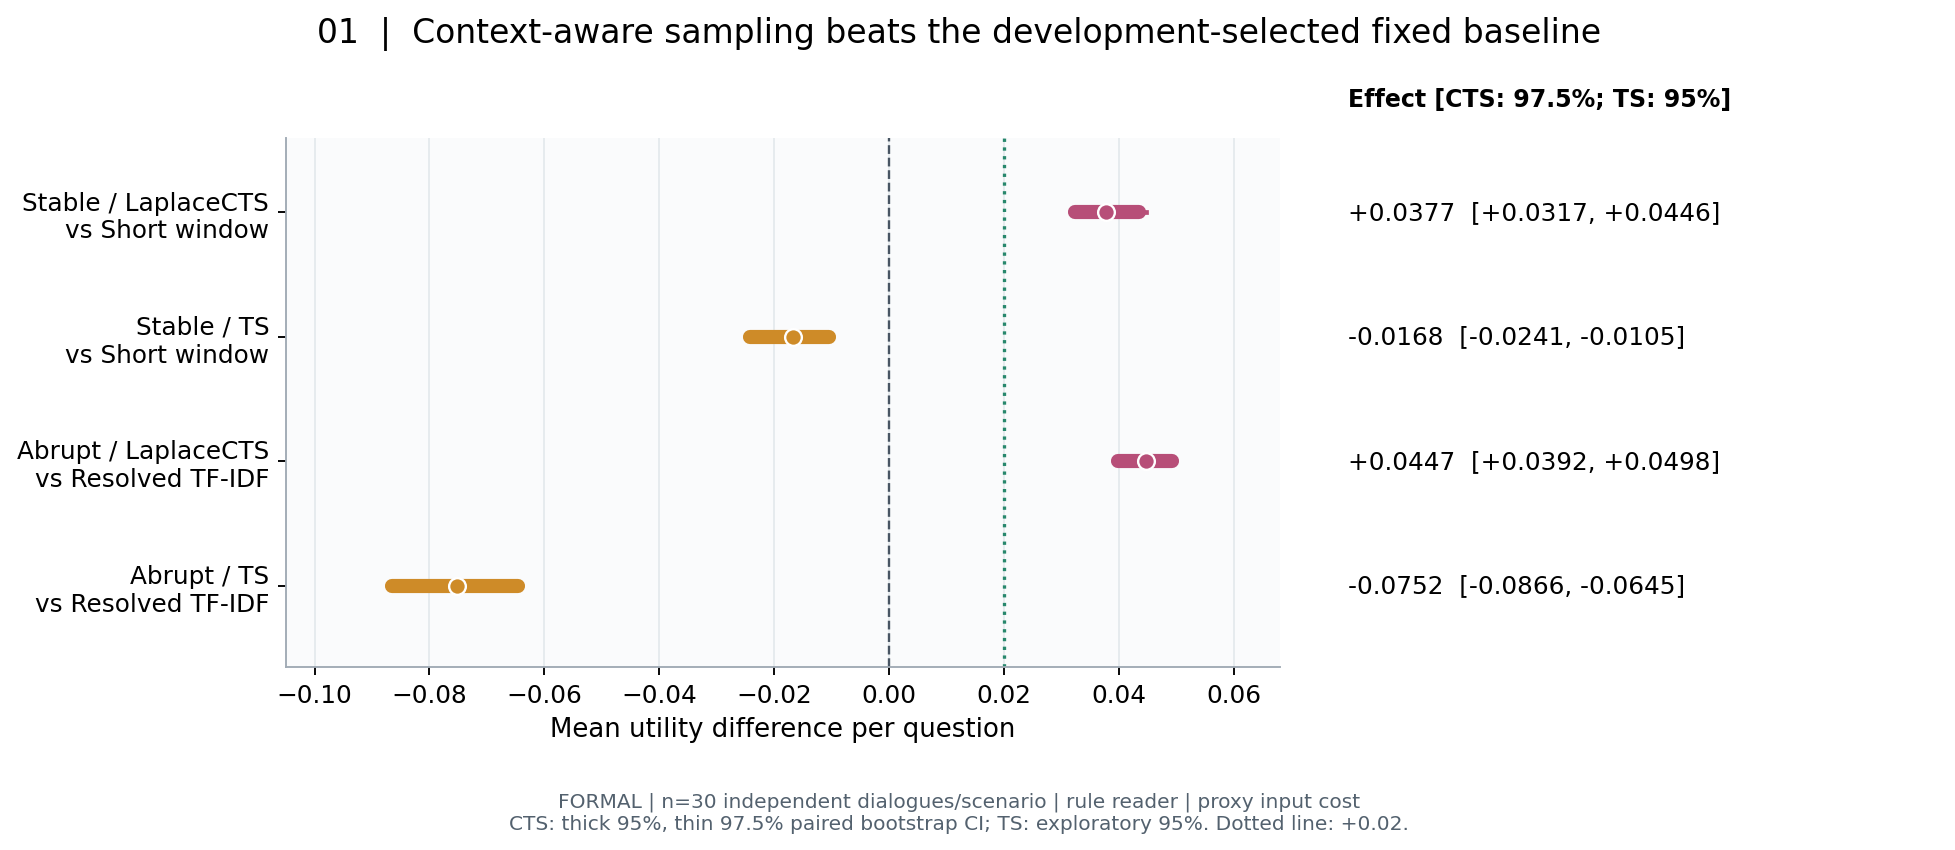

In [2]:
fig,(ax,tab)=plt.subplots(1,2,figsize=(12,5.1),gridspec_kw={'width_ratios':[1.65,1]})
fig.subplots_adjust(left=.17,right=.98,top=.82,bottom=.21,wspace=.07)
labels=[]; rows=[]
for sc in M5_SCENARIOS:
    for method,table in [('LaplaceCTS',M5_PRIMARY),('TS',M5_SECONDARY)]:
        r=table[table.scenario==sc].iloc[0]; y=len(rows);color=M5_COLORS[method]
        if method=='LaplaceCTS':
            ax.plot([r.family_low,r.family_high],[y,y],color=color,lw=2)
            lo,hi=r.family_low,r.family_high
        else:lo,hi=r.low,r.high
        ax.plot([r.low,r.high],[y,y],color=color,lw=6,solid_capstyle='round')
        ax.scatter(r.effect,y,s=50,color=color,edgecolors='white',zorder=3)
        labels.append(f'{sc.title()} / {method}\nvs {M5_NAMES[r.baseline]}')
        rows.append((r.effect,lo,hi))
ax.axvline(0,color='#485563',ls='--',lw=1)
ax.axvline(.02,color='#27876C',ls=':',lw=1.4)
ax.set(yticks=range(4),yticklabels=labels,ylim=(3.65,-.6),xlim=(-.105,.068),
       xlabel='Mean utility difference per question')
ax.grid(axis='x');tab.set(ylim=(3.65,-.6),xlim=(0,1));tab.axis('off')
tab.text(.02,-.85,'Effect [CTS: 97.5%; TS: 95%]',weight='bold',fontsize=10)
for y,(effect,lo,hi) in enumerate(rows):tab.text(.02,y,f'{effect:+.4f}  [{lo:+.4f}, {hi:+.4f}]',va='center',fontsize=10.5)
fig.suptitle('01  |  Context-aware sampling beats the development-selected fixed baseline',fontsize=14,y=.96)
m5_save(fig,'01_paired_effects','CTS: thick 95%, thin 97.5% paired bootstrap CI; TS: exploratory 95%. Dotted line: +0.02.')

### 图2 · 所有对照：效用、准确率与成本一起看
保留四个固定臂、TS、CTS及RuleRouter，避免只展示有利对照。误差线为各方法平均效用的描述性95%对话bootstrap区间；方法之间是否有差异，应看图1的配对差区间，不能依据两条独立区间是否重叠判断。

CTS并非最高准确率或最低成本的单项冠军，而是在两者之间取得较好效用。RuleRouter知道模板规则，在两个场景都高于CTS；这说明学习器仍付出探索/估计代价，且本任务存在更简单有效的人工路由参照。长窗成本高而收益不足，原始TF–IDF也并非强基线，主要结论必须保留resolved_TFIDF对照。

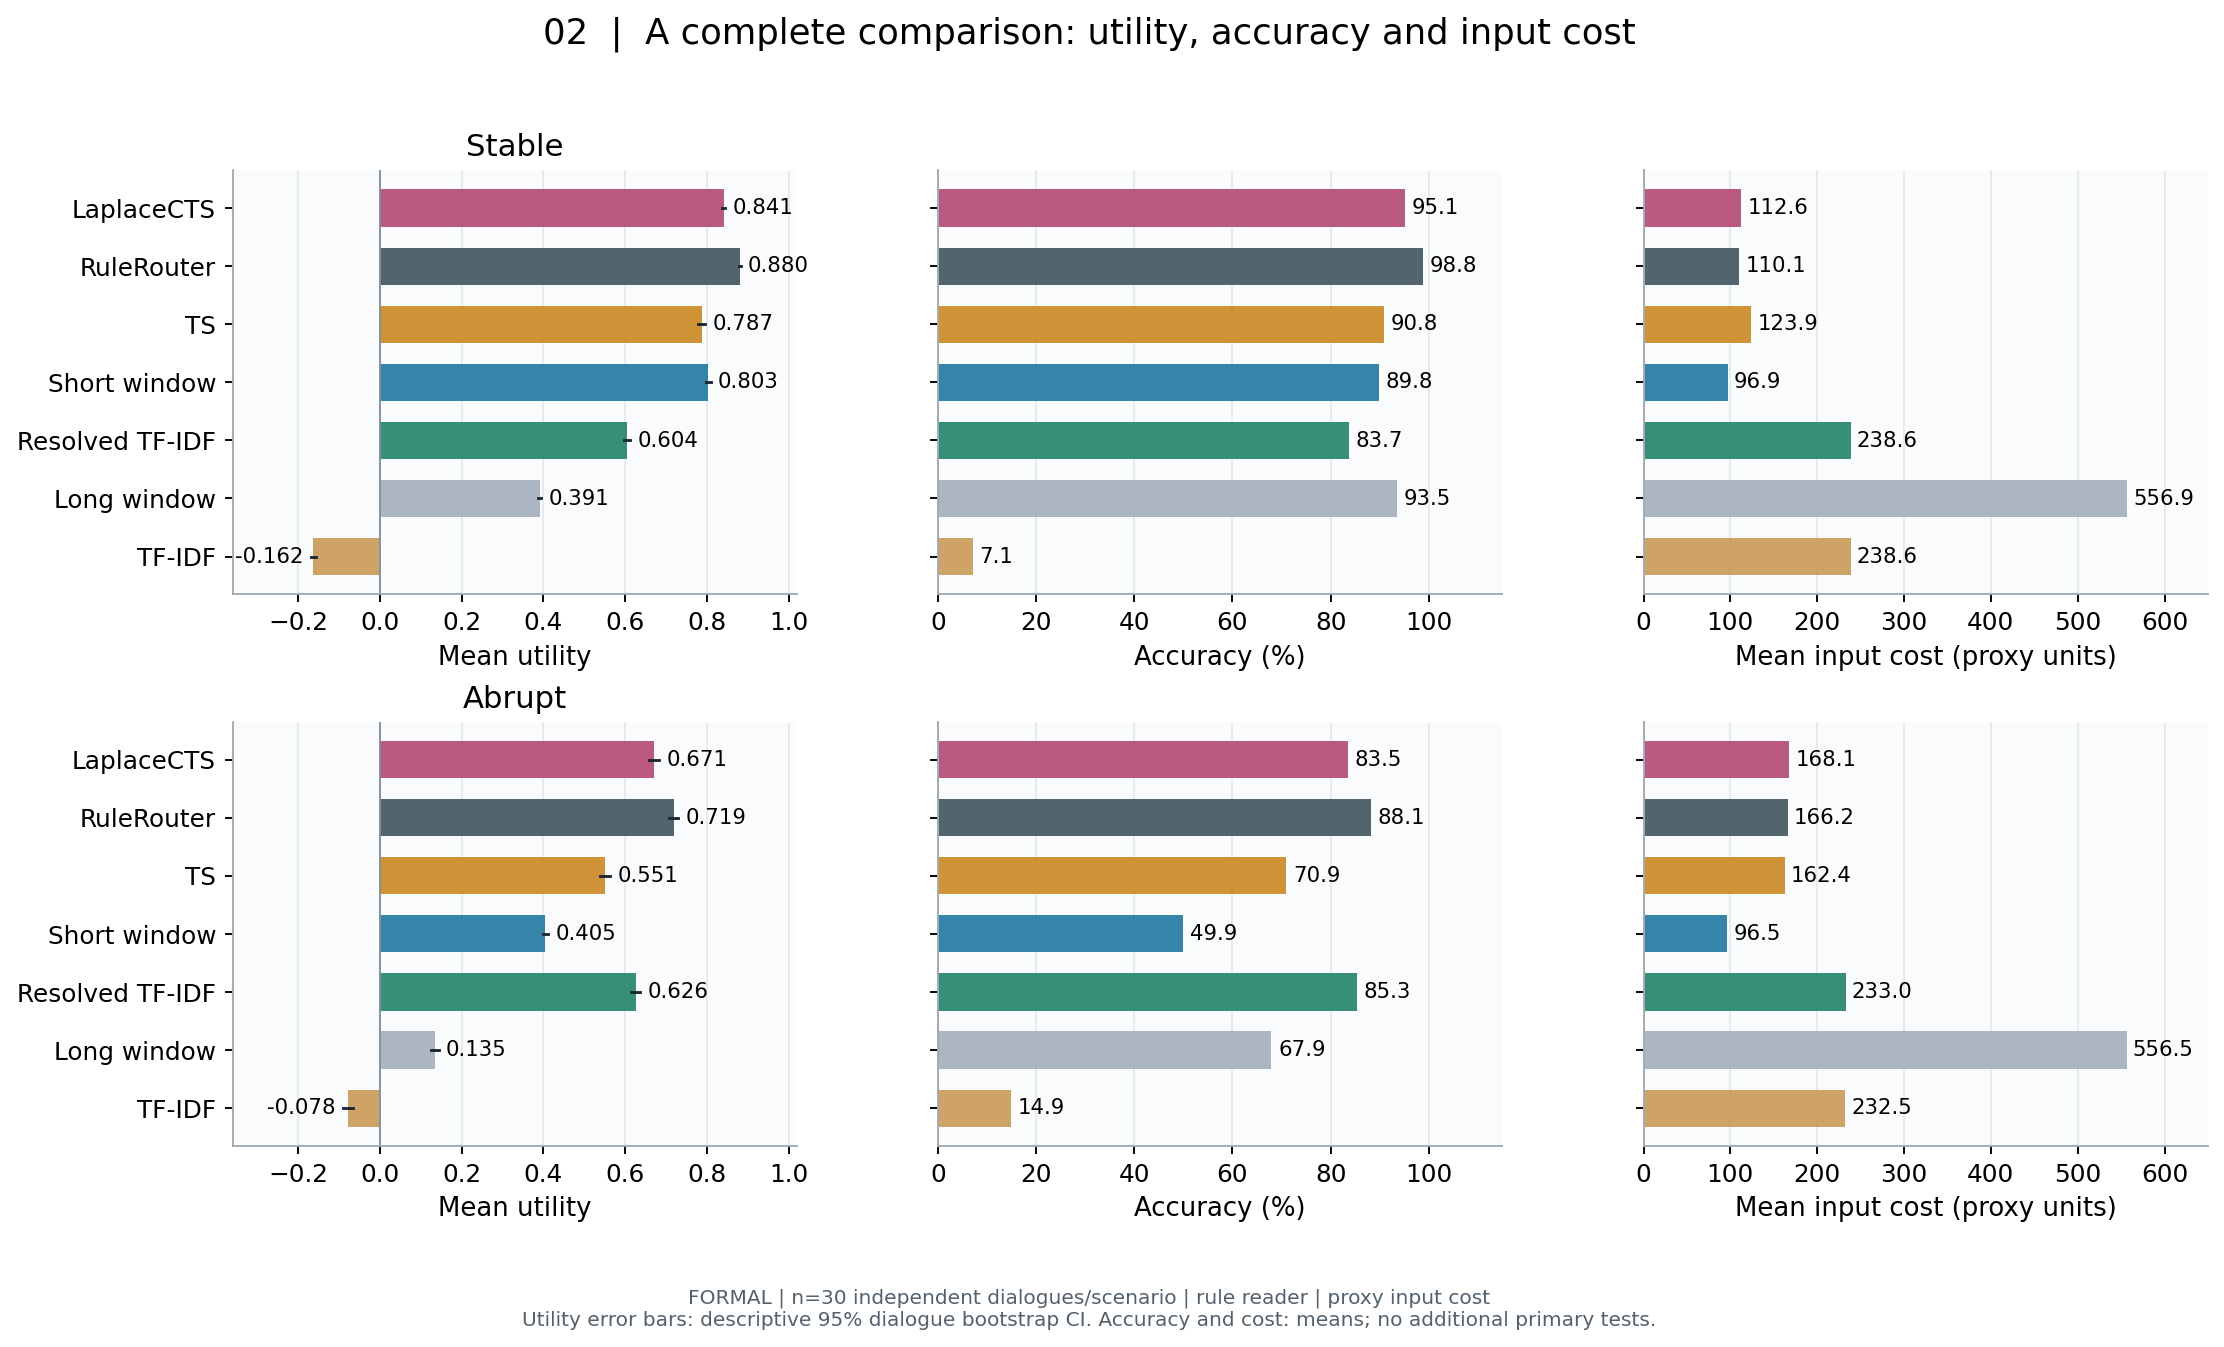

In [3]:
fig,axes=plt.subplots(2,3,figsize=(14,8.2),sharey=True)
fig.subplots_adjust(left=.14,right=.97,top=.85,bottom=.15,wspace=.25,hspace=.3)
yy=np.arange(len(M5_METHODS));colors=[M5_COLORS[m] for m in M5_METHODS]
for row,sc in enumerate(M5_SCENARIOS):
    s=M5_SUMMARY.loc[sc].reindex(M5_METHODS)
    for col,(metric,label,lim) in enumerate([('utility','Mean utility',(-.36,1.02)),('y','Accuracy (%)',(0,115)),('cost','Mean input cost (proxy units)',(0,650))]):
        ax=axes[row,col];values=s[metric].to_numpy()*(100 if metric=='y' else 1)
        ax.barh(yy,values,color=colors,height=.64,alpha=.93)
        if metric=='utility':
            ci=np.array([m5_boot_mean(M5_EP[(M5_EP.scenario==sc)&(M5_EP.method==m)].utility) for m in M5_METHODS])
            for j,(lo,hi) in enumerate(ci):ax.plot([lo,hi],[j,j],color='#182733',lw=1.2)
        for j,v in enumerate(values):
            offset=.012 if metric=='utility' else (1.4 if metric=='y' else 7)
            position=(max(v,ci[j,1])+.018 if v>=0 else min(v,ci[j,0])-.018) if metric=='utility' else (v+offset if v>=0 else v-offset)
            ax.text(position,j,f'{v:.3f}' if metric=='utility' else f'{v:.1f}',
                    ha='left' if v>=0 else 'right',va='center',fontsize=9)
        ax.axvline(0,color='#82919D',lw=.8);ax.grid(axis='x');ax.set_axisbelow(True)
        ax.set(xlim=lim,yticks=yy,yticklabels=[M5_NAMES[m] for m in M5_METHODS],xlabel=label,
               title=sc.title() if col==0 else '')
axes[0,0].invert_yaxis()
fig.suptitle('02  |  A complete comparison: utility, accuracy and input cost',fontsize=15,y=.96)
m5_save(fig,'02_all_method_metrics','Utility error bars: descriptive 95% dialogue bootstrap CI. Accuracy and cost: means; no additional primary tests.')

### 图3 · 收益来源：准确率收益减去成本变化
恒等式 $\Delta U=\Delta\mathrm{Accuracy}-0.5\Delta C/512$ 可以把主结果精确拆开。这里比较的是**同一场景的开发固定基线**，两场景的基线不同。

stable中CTS比短窗更准确，但使用更多输入，成本部分抵消准确率收益。abrupt中CTS比固定强检索略不准确，但节约输入的收益更大，因此总效用提升。不能把abrupt的正效用解释为“准确率也提高”。这是冻结λ=0.5时的结果，不是对任意成本权重的保证。

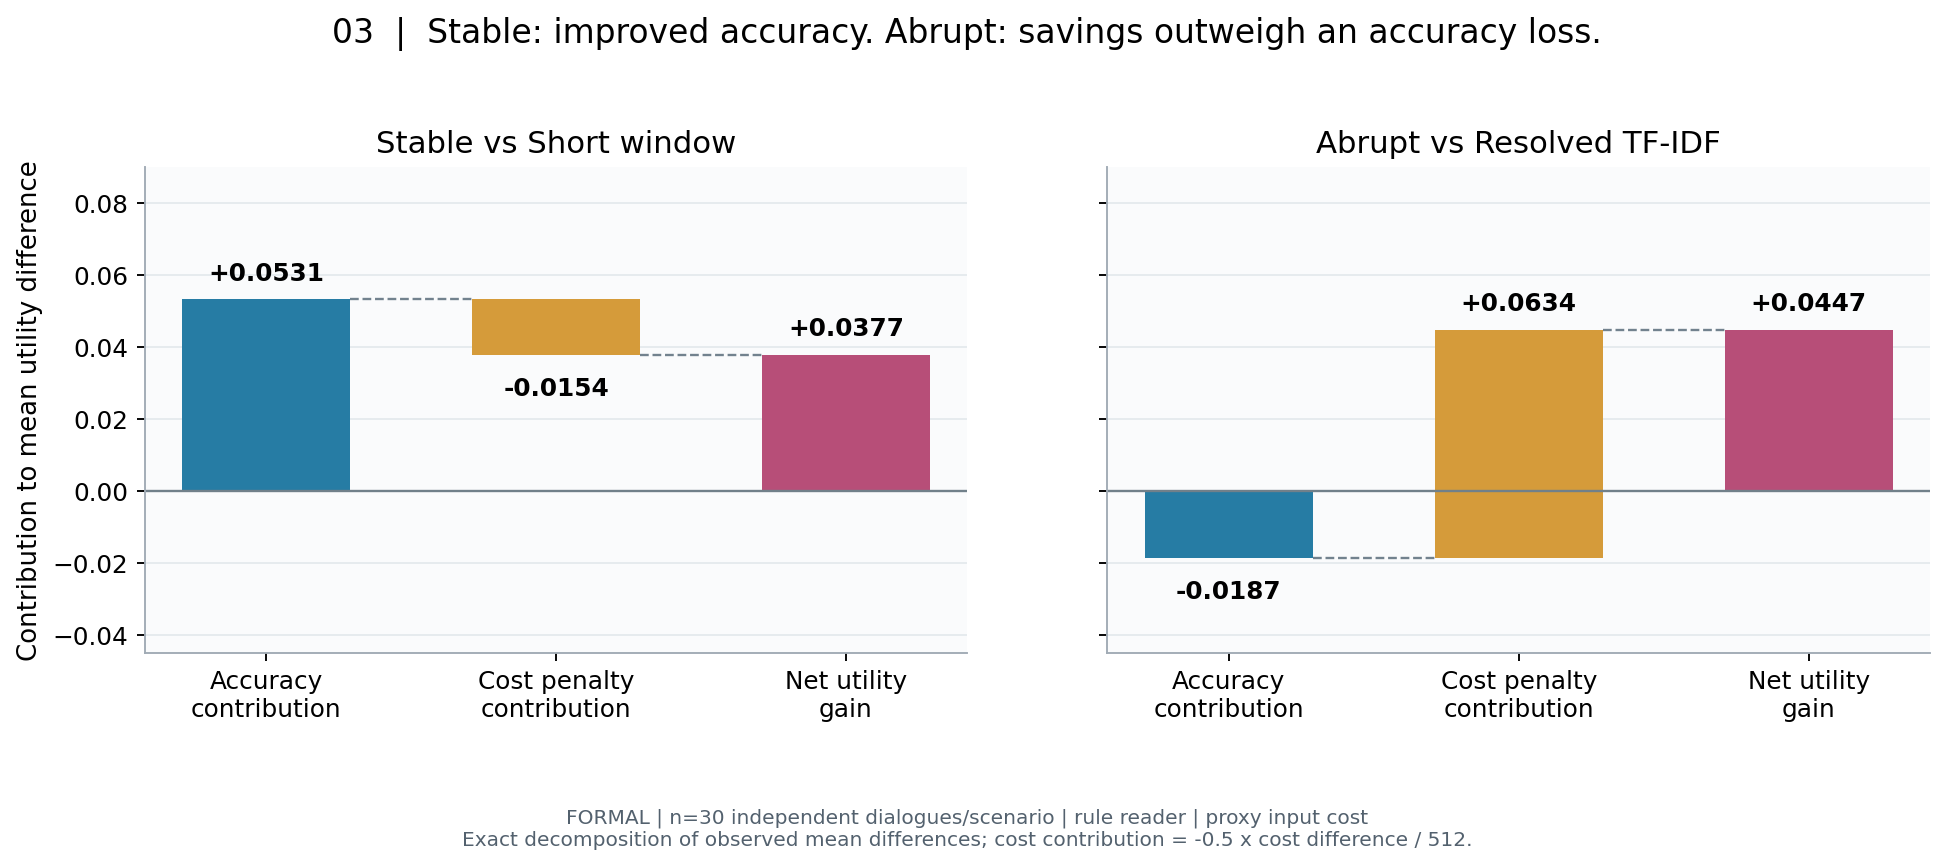

In [4]:
M5_DECOMP=[]
fig,axes=plt.subplots(1,2,figsize=(11.8,5.2),sharey=True)
fig.subplots_adjust(left=.09,right=.98,top=.79,bottom=.24,wspace=.17)
for ax,sc in zip(axes,M5_SCENARIOS):
    c=M5_SUMMARY.loc[(sc,'LaplaceCTS')];b=M5_SUMMARY.loc[(sc,M5_BEST[sc])]
    da=float(c.y-b.y);dc=float(-M5_CFG['lam']*(c.cost-b.cost)/M5_CFG['cref']);du=float(c.utility-b.utility)
    assert np.isclose(da+dc,du)
    M5_DECOMP.append(dict(scenario=sc,baseline=M5_BEST[sc],accuracy_delta=da,
                         cost_delta=float(c.cost-b.cost),cost_contribution=dc,utility_delta=du))
    ax.bar(0,da,color='#267CA4',width=.58)
    ax.bar(1,dc,bottom=da,color='#D59B3A',width=.58)
    ax.bar(2,du,color=M5_COLORS['LaplaceCTS'],width=.58)
    ax.plot([.29,.71],[da,da],color='#72828E',ls='--',lw=1)
    ax.plot([1.29,1.71],[du,du],color='#72828E',ls='--',lw=1)
    for j,value,endpoint in [(0,da,da),(1,dc,du),(2,du,du)]:
        ax.text(j,endpoint+(.004 if value>=0 else -.006),f'{value:+.4f}',ha='center',
                va='bottom' if value>=0 else 'top',weight='bold')
    ax.axhline(0,color='#71808A',lw=1);ax.grid(axis='y');ax.set_axisbelow(True)
    ax.set(xticks=[0,1,2],xticklabels=['Accuracy\ncontribution','Cost penalty\ncontribution','Net utility\ngain'],
           title=f'{sc.title()} vs {M5_NAMES[M5_BEST[sc]]}',ylim=(-.045,.09))
axes[0].set_ylabel('Contribution to mean utility difference')
fig.suptitle('03  |  Stable: improved accuracy. Abrupt: savings outweigh an accuracy loss.',fontsize=14,y=.96)
pd.DataFrame(M5_DECOMP).to_csv(M5_DIR/'utility_decomposition.csv',index=False)
m5_save(fig,'03_utility_decomposition','Exact decomposition of observed mean differences; cost contribution = -0.5 x cost difference / 512.')

### 图4 · 学到了怎样的选择行为？
每15题为一组，展示四臂选择比例。纵轴是动作比例，不是准确率。abrupt中竖线对应`t=150`、即第151题开始，近期题概率从90%变为10%。stable没有突变，不能在那里画同样的“切换线”。

CTS总体随问题需求改变选臂，TS对历史题与近期题的区分较弱。但这里变化的是**提问类型分布**；给定问题特征后的回答机制并未突变。因此更准确的表述是“CTS利用问题特征实现路由”，而非证明它能处理任意非平稳奖励或具有某个精确适应时间。

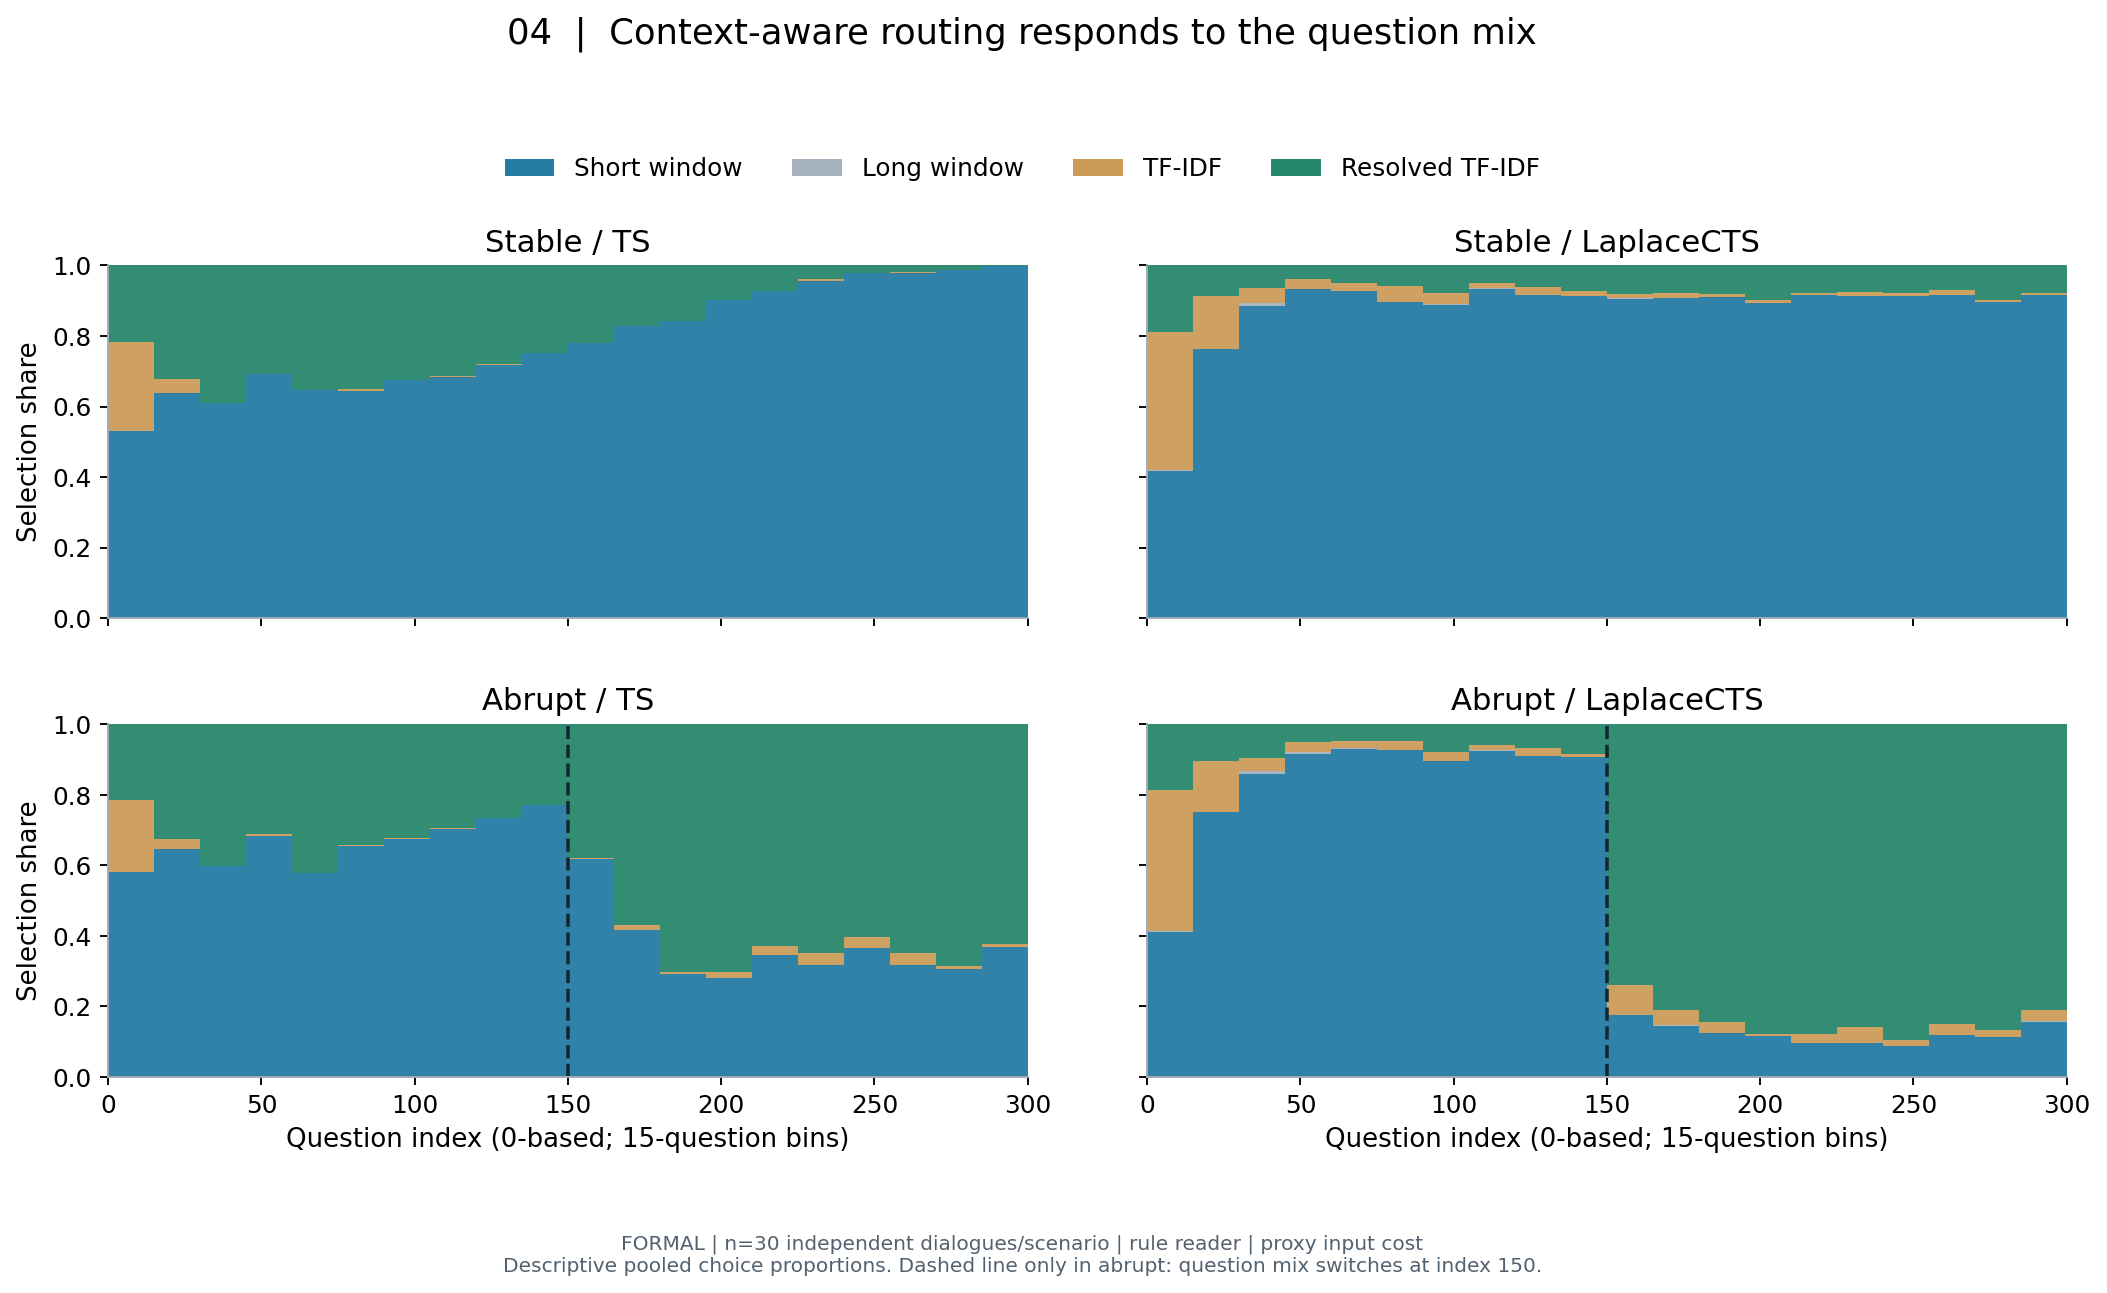

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12.8,7.7),sharex=True,sharey=True)
fig.subplots_adjust(left=.08,right=.98,top=.79,bottom=.17,hspace=.3,wspace=.13)
M5_SELECTION_BINS=[]
for row,sc in enumerate(M5_SCENARIOS):
    for col,method in enumerate(['TS','LaplaceCTS']):
        ax=axes[row,col];z=M5_REPLAY[(M5_REPLAY.scenario==sc)&(M5_REPLAY.method==method)].copy()
        z['bin']=z.t//15
        shares=pd.crosstab(z.bin,z.arm,normalize='index').reindex(columns=M5_ARMS,fill_value=0)
        assert np.allclose(shares.sum(axis=1),1)
        exported=shares.reset_index();exported['scenario']=sc;exported['method']=method;M5_SELECTION_BINS.append(exported)
        xx=np.r_[shares.index.to_numpy()*15,M5_CFG['T']]
        ax.stackplot(xx,*[np.r_[shares[a],shares[a].iloc[-1]] for a in M5_ARMS],step='post',
                     colors=[M5_COLORS[a] for a in M5_ARMS],alpha=.95)
        if sc=='abrupt':ax.axvline(M5_CFG['T']//2,color='#142631',ls='--',lw=1.5)
        ax.set(title=f'{sc.title()} / {method}',ylim=(0,1),xlim=(0,M5_CFG['T']))
        if col==0:ax.set_ylabel('Selection share')
        if row==1:ax.set_xlabel('Question index (0-based; 15-question bins)')
fig.legend(handles=[Patch(facecolor=M5_COLORS[a],label=M5_NAMES[a]) for a in M5_ARMS],
           loc='upper center',bbox_to_anchor=(.5,.89),ncol=4,frameon=False)
fig.suptitle('04  |  Context-aware routing responds to the question mix',fontsize=15,y=.98)
pd.concat(M5_SELECTION_BINS).to_csv(M5_DIR/'selection_15_question_bins.csv',index=False)
m5_save(fig,'04_selection_over_time','Descriptive pooled choice proportions. Dashed line only in abrupt: question mix switches at index 150.')

### 图5 · 累计收益轨迹：收益是否贯穿对话？
每条对话内先平均两个算法种子的逐题效用，再减同一条对话固定基线的效用、计算累积和；最后跨对话求均值。淡色带为**逐时点**95%配对对话bootstrap区间，不是整条曲线同时覆盖的区间，不能用于反复挑选显著时间点。

CTS累计优势与图1的平均收益一致，RuleRouter累计收益更高。突变后仍应关注曲线斜率，而不只看此前已经积累的正值；具体前后阶段差异见图7。本图是相对开发固定基线的累计效用差，**不是理论regret**。

/var/folders/_4/vxs3bmc96mv4cy8flx587vlr0000gn/T/ipykernel_60858/4119458676.py:13: RuntimeWarning: divide by zero encountered in matmul
  lo,hi=np.quantile(weights@values,[.025,.975],axis=0)
/var/folders/_4/vxs3bmc96mv4cy8flx587vlr0000gn/T/ipykernel_60858/4119458676.py:13: RuntimeWarning: overflow encountered in matmul
  lo,hi=np.quantile(weights@values,[.025,.975],axis=0)
/var/folders/_4/vxs3bmc96mv4cy8flx587vlr0000gn/T/ipykernel_60858/4119458676.py:13: RuntimeWarning: invalid value encountered in matmul
  lo,hi=np.quantile(weights@values,[.025,.975],axis=0)
/var/folders/_4/vxs3bmc96mv4cy8flx587vlr0000gn/T/ipykernel_60858/4119458676.py:13: RuntimeWarning: divide by zero encountered in matmul
  lo,hi=np.quantile(weights@values,[.025,.975],axis=0)
/var/folders/_4/vxs3bmc96mv4cy8flx587vlr0000gn/T/ipykernel_60858/4119458676.py:13: RuntimeWarning: overflow encountered in matmul
  lo,hi=np.quantile(weights@values,[.025,.975],axis=0)
/var/folders/_4/vxs3bmc96mv4cy8flx587vlr0000gn/T/ipykernel

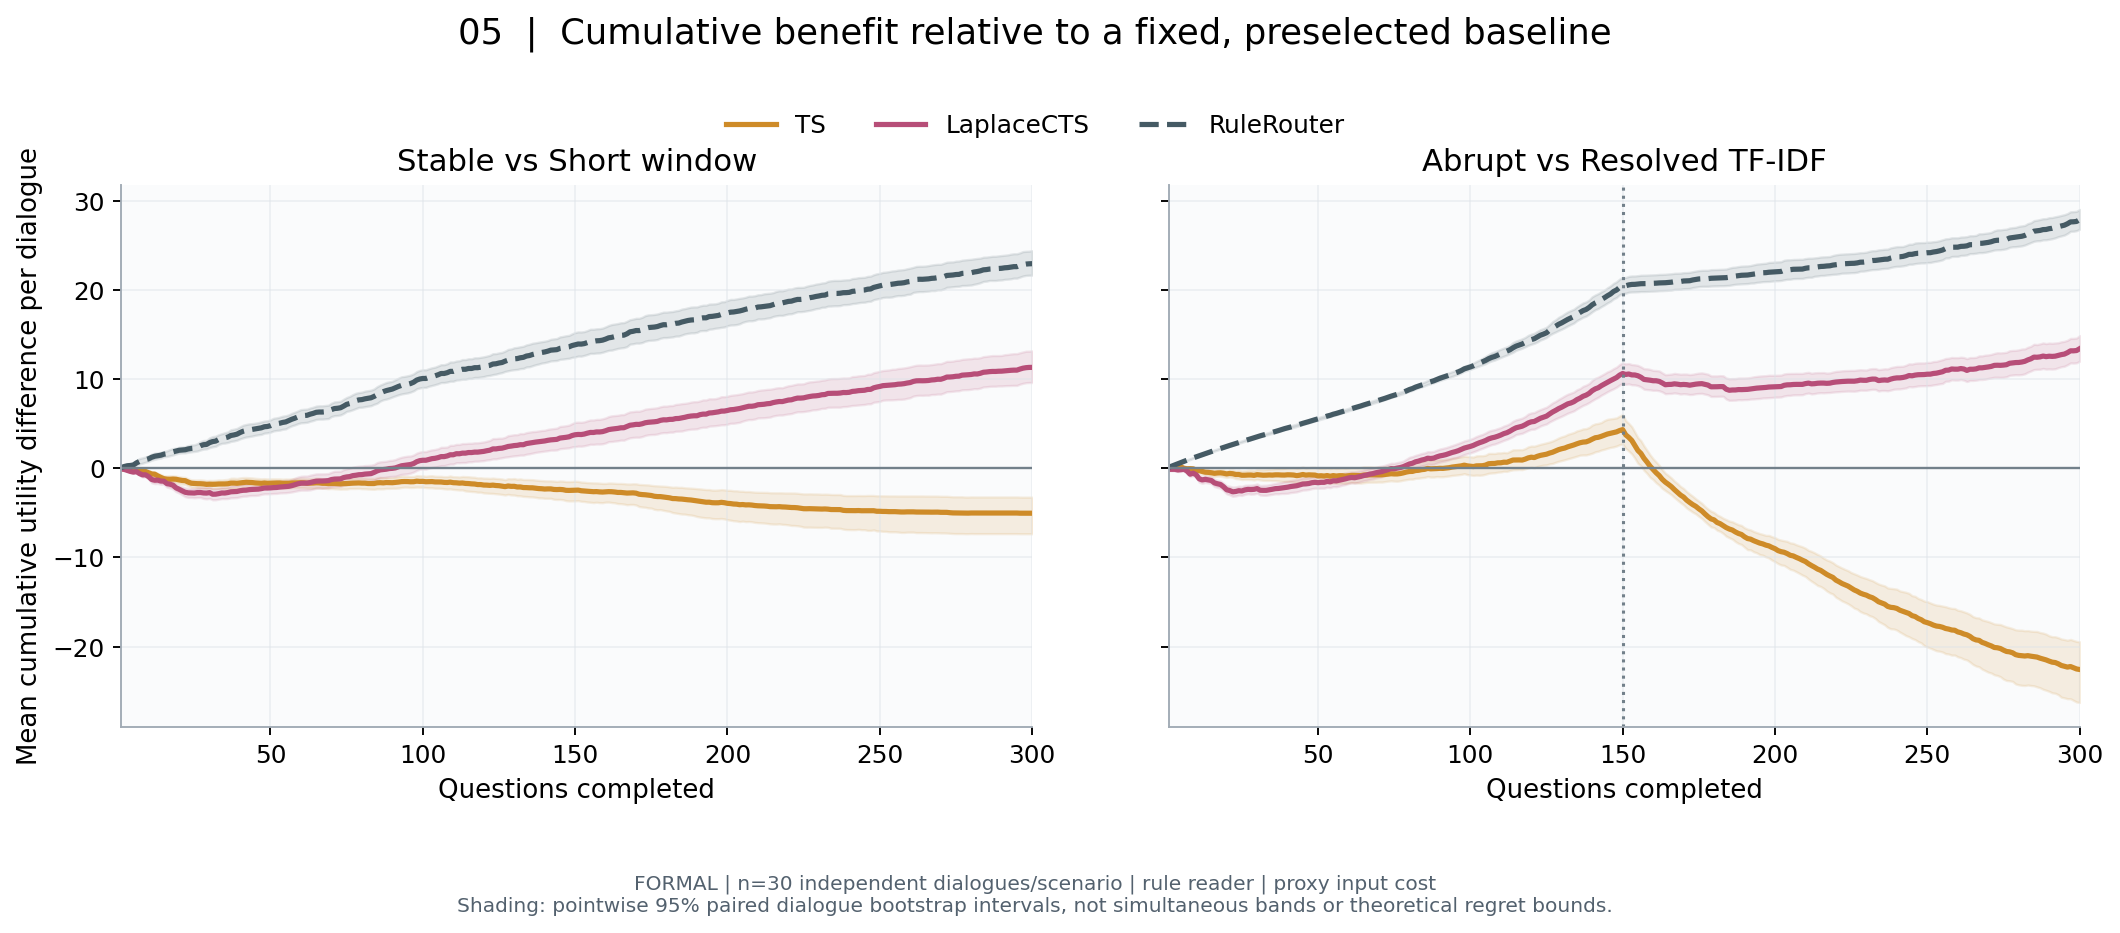

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12.8,5.5),sharey=True)
fig.subplots_adjust(left=.08,right=.98,top=.8,bottom=.22,wspace=.15)
M5_CURVES=[]
for ax,sc in zip(axes,M5_SCENARIOS):
    z=M5_REPLAY[M5_REPLAY.scenario==sc].groupby(['seed','t','method']).utility.mean().unstack('method')
    for method in ['TS','LaplaceCTS','RuleRouter']:
        per=(z[method]-z[M5_BEST[sc]]).unstack('t').sort_index(axis=1).cumsum(axis=1)
        assert per.shape==(M5_N,M5_CFG['T'])
        values=per.to_numpy();mean=values.mean(axis=0)
        # 与整条对话重采样等价的计数权重；不重采样单题。
        rng=np.random.default_rng(2026)
        weights=rng.multinomial(M5_N,np.full(M5_N,1/M5_N),size=2000)/M5_N
        lo,hi=np.quantile(weights@values,[.025,.975],axis=0)
        xx=np.arange(1,M5_CFG['T']+1)
        ax.fill_between(xx,lo,hi,color=M5_COLORS[method],alpha=.13)
        ax.plot(xx,mean,label=method,color=M5_COLORS[method],lw=2.2,ls='--' if method=='RuleRouter' else '-')
        for t,m,l,h in zip(xx,mean,lo,hi):M5_CURVES.append(dict(scenario=sc,method=method,questions_completed=int(t),mean=m,low=l,high=h))
        if method=='LaplaceCTS':assert np.isclose(mean[-1]/M5_CFG['T'],M5_PRIMARY.set_index('scenario').loc[sc,'effect'])
    ax.axhline(0,color='#72808A',lw=1)
    if sc=='abrupt':ax.axvline(M5_CFG['T']//2,color='#72808A',ls=':',lw=1.3)
    ax.set(title=f'{sc.title()} vs {M5_NAMES[M5_BEST[sc]]}',xlabel='Questions completed',xlim=(1,M5_CFG['T']))
    ax.grid(alpha=.45)
axes[0].set_ylabel('Mean cumulative utility difference per dialogue')
fig.legend(*axes[0].get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.5,.9),ncol=3,frameon=False)
fig.suptitle('05  |  Cumulative benefit relative to a fixed, preselected baseline',fontsize=15,y=.98)
pd.DataFrame(M5_CURVES).to_csv(M5_DIR/'cumulative_difference_bands.csv',index=False)
m5_save(fig,'05_cumulative_utility','Shading: pointwise 95% paired dialogue bootstrap intervals, not simultaneous bands or theoretical regret bounds.')

### 图6 · 策略为何有互补性？
这张热图直接用正式数据的四臂反事实结果，按近期题/历史题统计准确率。它解释策略可利用的取舍，但学习器运行时**没有同时看到四臂奖励**。该分析为描述性，未增加主假设检验。

短窗对近期题几乎理想，对历史题则缺少证据；强检索能找回历史事实，但仍会误取旧版本。TF–IDF即便取到某条有效事实，也可能缺失最新focus而错误解释its，所以“证据覆盖”不等于“回答正确”。任务结构明显有利于按问题类型路由，这既解释正结果，也限制真实场景外推。

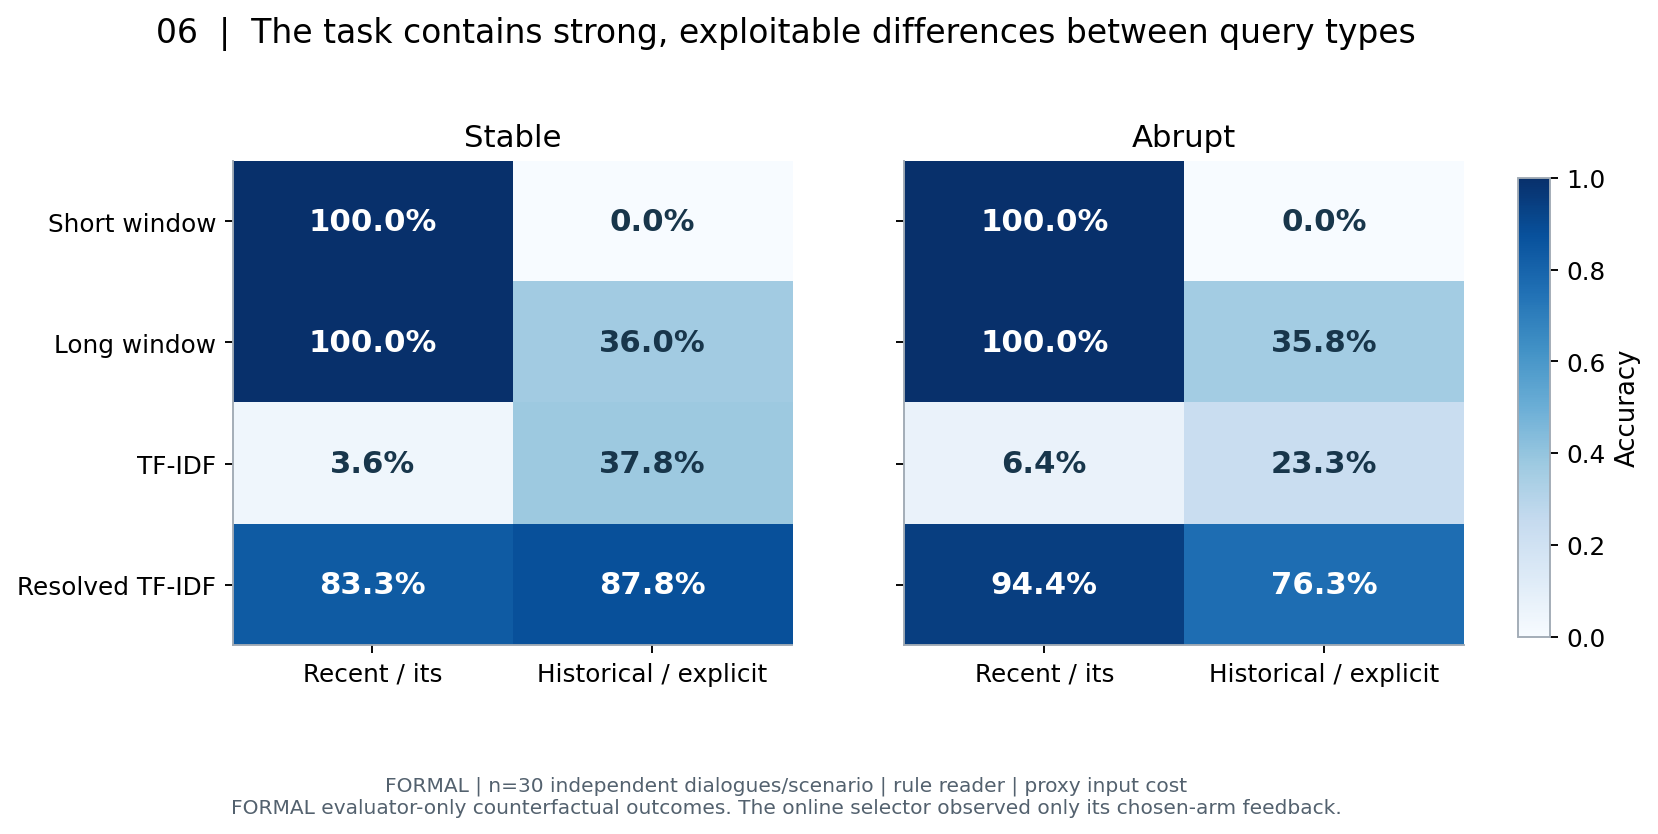

In [7]:
M5_ARM_QUERY=M5_OUTCOMES.groupby(['scenario','arm','qtype'])[['y','outdated','coverage','cost']].mean()
M5_ARM_QUERY.to_csv(M5_DIR/'formal_arm_by_question.csv')
fig,axes=plt.subplots(1,2,figsize=(10.5,5),sharey=True)
fig.subplots_adjust(left=.19,right=.88,top=.79,bottom=.22,wspace=.2)
for ax,sc in zip(axes,M5_SCENARIOS):
    z=M5_ARM_QUERY.loc[sc].y.unstack('qtype').reindex(index=M5_ARMS,columns=['recent','historical'])
    im=ax.imshow(z,vmin=0,vmax=1,cmap='Blues',aspect='auto')
    for i in range(4):
        for j in range(2):ax.text(j,i,f'{z.iloc[i,j]:.1%}',ha='center',va='center',fontsize=13,
                                  color='white' if z.iloc[i,j]>.55 else '#18364B',weight='bold')
    ax.set(xticks=[0,1],xticklabels=['Recent / its','Historical / explicit'],yticks=range(4),
           yticklabels=[M5_NAMES[a] for a in M5_ARMS],title=sc.title())
cax=fig.add_axes([.91,.23,.018,.54]);fig.colorbar(im,cax=cax,label='Accuracy')
fig.suptitle('06  |  The task contains strong, exploitable differences between query types',fontsize=14,y=.96)
m5_save(fig,'06_arm_accuracy_by_question','FORMAL evaluator-only counterfactual outcomes. The online selector observed only its chosen-arm feedback.')

### 图7 · 突变前后：正收益不等于两个阶段同样强
比较CTS/TS/RuleRouter相对同一个开发强检索基线的效用差，分前150题与后150题。区间仍按独立对话配对计算，**95%区间仅作事后描述，没有多重比较校正**，不替代图1。

CTS在abrupt前半段的平均优势约+0.07090，后半段约+0.01854。全程的+0.04472并不表示后半段同样超过0.02。后半段CTS与强检索的平均准确率同为72.93%，优势主要来自更低输入成本；因此项目能支持整体路由收益，但“突变后大幅提升准确率”并不成立。

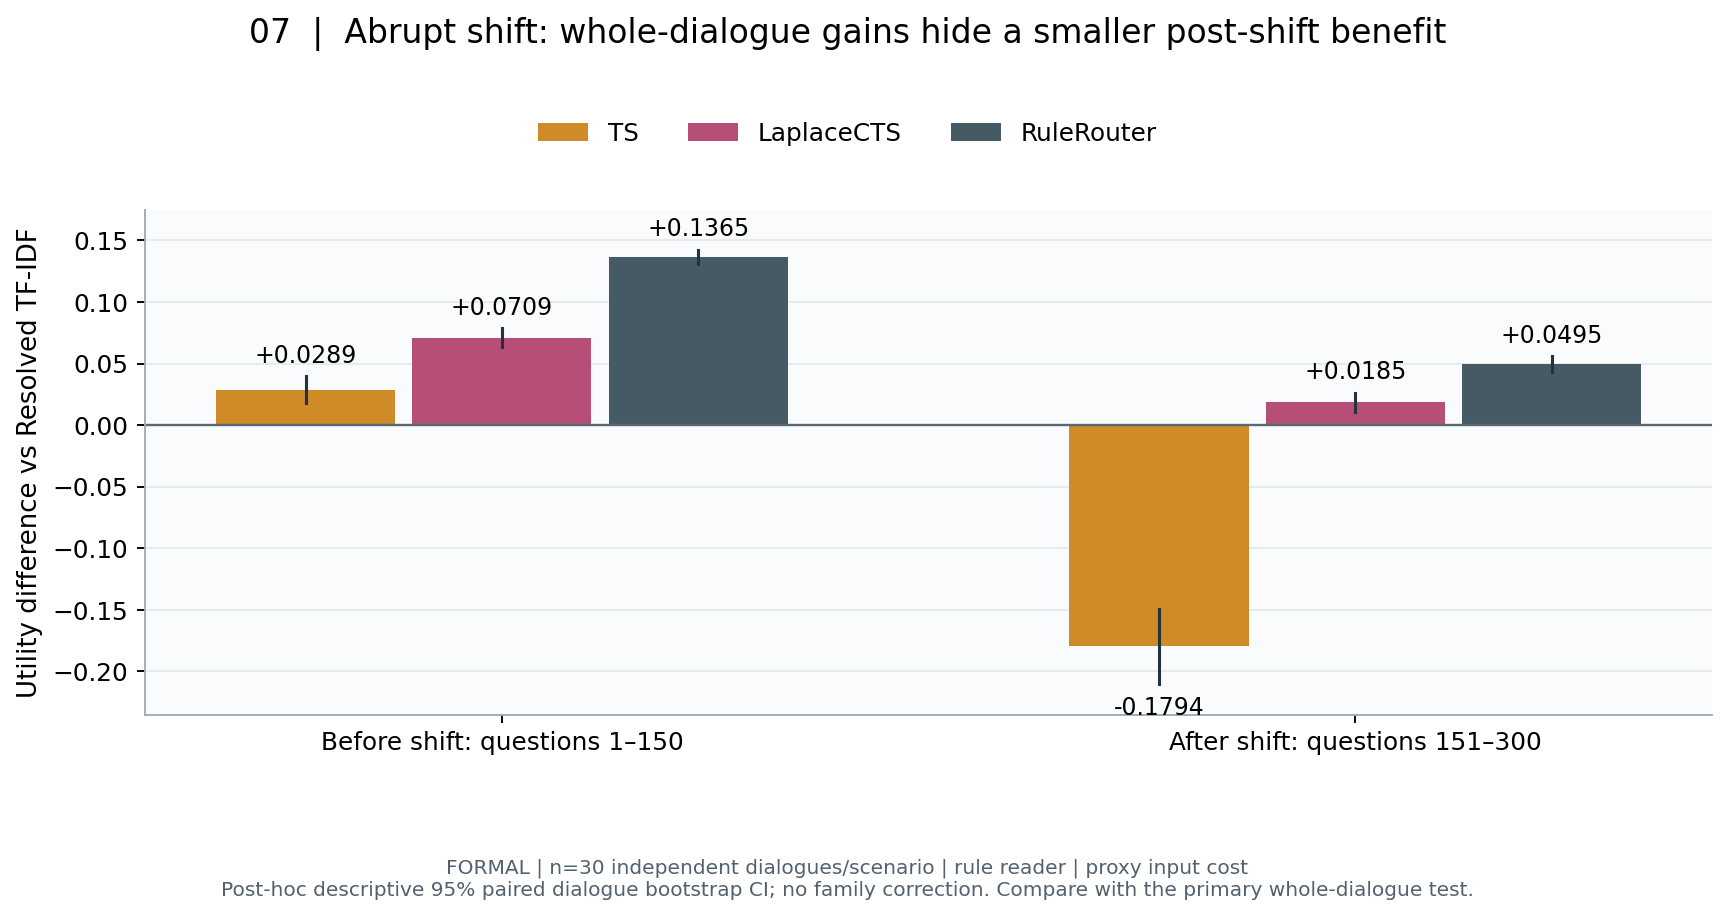

In [8]:
M5_PHASE_EFFECTS=[]
z=M5_REPLAY[M5_REPLAY.scenario=='abrupt'].copy();z['phase']=np.where(z.t<M5_CFG['T']//2,'before','after')
p=z.groupby(['seed','phase','method']).utility.mean().unstack('method')
fig,ax=plt.subplots(figsize=(10.6,5.4));fig.subplots_adjust(left=.11,right=.98,top=.77,bottom=.22)
for j,method in enumerate(['TS','LaplaceCTS','RuleRouter']):
    means=[];bounds=[]
    for phase in ['before','after']:
        g=p.xs(phase,level='phase');d=g[method]-g[M5_BEST['abrupt']];lo,hi=m5_boot_mean(d)
        mean=float(d.mean());means.append(mean);bounds.append([lo,hi])
        M5_PHASE_EFFECTS.append(dict(method=method,phase=phase,effect=mean,low=float(lo),high=float(hi),n=len(d),analysis='post-hoc descriptive, unadjusted 95% paired dialogue bootstrap'))
    xx=np.arange(2)+(j-1)*.23;bounds=np.array(bounds)
    ax.bar(xx,means,width=.21,color=M5_COLORS[method],label=method)
    for x0,(lo,hi) in zip(xx,bounds):ax.plot([x0,x0],[lo,hi],color='#23333E',lw=1.3)
    for x0,mean,(lo,hi) in zip(xx,means,bounds):ax.text(x0,hi+.007 if mean>=0 else lo-.009,f'{mean:+.4f}',ha='center',va='bottom' if mean>=0 else 'top',fontsize=10)
ax.axhline(0,color='#596874',lw=1);ax.set(xticks=[0,1],xticklabels=['Before shift: questions 1–150','After shift: questions 151–300'],
    ylabel='Utility difference vs Resolved TF-IDF',ylim=(-.235,.175))
ax.grid(axis='y');ax.set_axisbelow(True)
fig.legend(*ax.get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.5,.89),ncol=3,frameon=False)
fig.suptitle('07  |  Abrupt shift: whole-dialogue gains hide a smaller post-shift benefit',fontsize=14,y=.98)
pd.DataFrame(M5_PHASE_EFFECTS).to_csv(M5_DIR/'phase_effects_descriptive.csv',index=False)
m5_save(fig,'07_before_after_effects','Post-hoc descriptive 95% paired dialogue bootstrap CI; no family correction. Compare with the primary whole-dialogue test.')

### 对本项目结果的评价
**总体判断：课程项目的实验主线成立，结果较好，证据与实现相互对应；研究贡献应定位为可复现的受控模拟验证。**

1. **结果与研究问题吻合。** 两个预先确定场景中CTS都优于开发阶段选定的固定基线，且校正区间下界超过0.02；同时保留TS负结果和RuleRouter更优结果，结论不是只挑有利对照。
2. **价值不只是显著性。** 开发/正式隔离、只接收所选臂反馈、独立真值审计、对话级配对统计和完整复现使证据可检查。图3解释“为什么赢”，图7说明“哪里赢得较少”。
3. **不能称为新算法突破或真实LLM验证。** CTS组合了已有贝叶斯logistic近似与后验采样；近期/历史模板几乎直接被显式项目名与its特征区分。RuleRouter利用这一结构仍优于CTS，说明该机制下学习的复杂性未必是部署时的最佳选择。
4. **方法比较有局限。** TS和CTS不仅特征不同，模型族也不同；没有同族无特征消融，不能把全部增益因果归于问题特征。成本λ只固定为0.5，缺少预先设计的权重敏感性实验。长窗/原始TF–IDF较弱，因此强检索与RuleRouter必须保留。
5. **统计和实际系统边界清楚。** 每场景n=30，区间依赖bootstrap近似并条件于两个既定算法种子；数据为规则模板，反馈即时且无噪声；每轮先构造四候选，proxy输入长度节省不等于端到端延迟或真实费用节省。

**最稳妥的结论措辞：**“在本研究预设的合成长对话与规则回答器下，LaplaceCTS在两个需求场景中提高了相对开发选定固定策略的平均成本惩罚效用；收益来源随场景不同。该结果支持问题相关路由的可行性，但尚不足以证明真实LLM系统收益、纯特征因果效应或任意非平稳环境的适应能力。”

后续如继续研究，优先增加同族无特征消融、预先固定的λ敏感性实验，以及更丰富模板/真实回答器验证。现有正式结果已查看，这些应单列为探索或使用新冻结测试集；不修改当前主结果来追求更大收益。

In [9]:
# 从实际CSV生成评价数值；归档图表清单与M4来源，保持M4目录不变。
M5_REPORT=['# M5 实验可视化与结果评价','',f'来源：`{M5_SOURCE}`。阶段：{M5_MODE}，每场景n={M5_N}。',
    '本次只新增图表和评价；slides与视频尚未制作。','',
    '| 场景 | 固定基线 | CTS效用差 | 校正97.5%区间 | CTS准确率 | 基线准确率 | CTS相对RuleRouter效用差 |',
    '|---|---|---:|---|---:|---:|---:|']
for r in M5_PRIMARY.itertuples():
    c=M5_SUMMARY.loc[(r.scenario,'LaplaceCTS')]; b=M5_SUMMARY.loc[(r.scenario,r.baseline)]; rr=M5_SUMMARY.loc[(r.scenario,'RuleRouter')]
    M5_REPORT.append(f'| {r.scenario} | {r.baseline} | {r.effect:+.5f} | [{r.family_low:.5f}, {r.family_high:.5f}] | {c.y:.2%} | {b.y:.2%} | {c.utility-rr.utility:+.5f} |')
M5_REPORT+=['','## 图表索引']
captions=['主次比较与区间','全方法效用/准确率/成本','收益来源分解','随时间的选臂比例','累计效用差及逐点区间','按问题类型的四臂准确率','突变前后效应（描述性）']
for name,caption in zip(M5_FIGURES,captions):M5_REPORT.append(f'- [{caption}]({name}.png)（另有同名SVG）')
M5_REPORT+=['','## 评价',
    '课程项目的实验主线成立，结果较好；定位应为可复现的受控模拟，而非新算法突破或真实LLM系统验证。',
    '两个场景的CTS主效应及校正区间支持正收益；TS低于固定基线，RuleRouter高于CTS，必须共同报告。',
    'stable的收益来自准确率提升抵消额外输入成本；abrupt的收益来自成本节约超过准确率损失。',
    'abrupt突变前后CTS效用差分别为'+', '.join(f"{r['phase']} {r['effect']:+.5f}" for r in M5_PHASE_EFFECTS if r['method']=='LaplaceCTS')+'；后半段收益小于全程均值，不能声称两个阶段都达到0.02。',
    '关键限制：特征近乎标识模板题型、人工多旧版本、规则回答器、即时无噪声反馈、两个固定算法种子、proxy成本、全部四候选的构造开销。',
    'TS与CTS模型族不同，无严格的同族特征消融；λ=.5条件下的结果不能外推任意成本权重。',
    '图2/图5/图7区间是描述性区间；累计曲线区间为逐点区间，不是同时置信带或理论regret界。',
    '下一步可单列探索：同族无特征消融、λ敏感性、更丰富模板或真实回答器；已查看测试集后不能把这些伪装为原确认性主检验。']
report='\n'.join(M5_REPORT)+'\n';(M5_DIR/'M5_results_evaluation.md').write_text(report,encoding='utf-8')
M5_NOTEBOOK=json.loads(Path('ARIN7101_Context_Bandit_Team_Notebook.ipynb').read_text())
m5_cells=[c for c in M5_NOTEBOOK['cells'] if 'm5' in c.get('metadata',{}).get('tags',[])]
m5_source='\n\n'.join(''.join(c['source']) for c in m5_cells if c['cell_type']=='code')
(M5_DIR/'m5_source.py').write_text(m5_source,encoding='utf-8')
assert len(M5_FIGURES)==7
assert len(list(M5_DIR.glob('*.png')))==len(list(M5_DIR.glob('*.svg')))==7
for name,sha in M5_MANIFEST['files'].items():assert m5_sha(M5_SOURCE/name)==sha
M5_RECORD=dict(status='complete',stage='M5 visualization and evaluation only',
    created_at_hong_kong=datetime.now(ZoneInfo('Asia/Hong_Kong')).isoformat(),
    source_run=str(M5_SOURCE),source_manifest_sha256=m5_sha(M5_SOURCE/'manifest.json'),
    source_code_sha256=M5_MANIFEST['code_sha256'],m5_code_sha256=hashlib.sha256(m5_source.encode()).hexdigest(),
    mode=M5_MODE,n_dialogues_per_scenario=M5_N,figures=M5_FIGURES,
    png_count=7,svg_count=7,slides_or_video_created=False,original_archive_unchanged=True,
    runtime_seconds=time.perf_counter()-M5_STARTED,
    versions={'numpy':np.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__},
    checks=['source archive SHA256 before and after plotting','dialogue sample size',
            'utility decomposition identity','selection shares sum to one',
            'cumulative final gain agrees with primary effect','seven PNG/SVG pairs'],
    files={p.name:m5_sha(p) for p in sorted(M5_DIR.iterdir()) if p.is_file()})
(M5_DIR/'manifest_m5.json').write_text(json.dumps(M5_RECORD,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
display(Markdown(report))
print('M5 complete:',M5_DIR.resolve())

# M5 实验可视化与结果评价

来源：`arin7101_team_outputs/formal_m1_m4_20261105`。阶段：formal，每场景n=30。
本次只新增图表和评价；slides与视频尚未制作。

| 场景 | 固定基线 | CTS效用差 | 校正97.5%区间 | CTS准确率 | 基线准确率 | CTS相对RuleRouter效用差 |
|---|---|---:|---|---:|---:|---:|
| stable | recent_short | +0.03774 | [0.03166, 0.04464] | 95.12% | 89.81% | -0.03878 |
| abrupt | resolved_tfidf | +0.04472 | [0.03921, 0.04978] | 83.47% | 85.34% | -0.04827 |

## 图表索引
- [主次比较与区间](01_paired_effects.png)（另有同名SVG）
- [全方法效用/准确率/成本](02_all_method_metrics.png)（另有同名SVG）
- [收益来源分解](03_utility_decomposition.png)（另有同名SVG）
- [随时间的选臂比例](04_selection_over_time.png)（另有同名SVG）
- [累计效用差及逐点区间](05_cumulative_utility.png)（另有同名SVG）
- [按问题类型的四臂准确率](06_arm_accuracy_by_question.png)（另有同名SVG）
- [突变前后效应（描述性）](07_before_after_effects.png)（另有同名SVG）

## 评价
课程项目的实验主线成立，结果较好；定位应为可复现的受控模拟，而非新算法突破或真实LLM系统验证。
两个场景的CTS主效应及校正区间支持正收益；TS低于固定基线，RuleRouter高于CTS，必须共同报告。
stable的收益来自准确率提升抵消额外输入成本；abrupt的收益来自成本节约超过准确率损失。
abrupt突变前后CTS效用差分别为before +0.07090, after +0.01854；后半段收益小于全程均值，不能声称两个阶段都达到0.02。
关键限制：特征近乎标识模板题型、人工多旧版本、规则回答器、即时无噪声反馈、两个固定算法种子、proxy成本、全部四候选的构造开销。
TS与CTS模型族不同，无严格的同族特征消融；λ=.5条件下的结果不能外推任意成本权重。
图2/图5/图7区间是描述性区间；累计曲线区间为逐点区间，不是同时置信带或理论regret界。
下一步可单列探索：同族无特征消融、λ敏感性、更丰富模板或真实回答器；已查看测试集后不能把这些伪装为原确认性主检验。


M5 complete: /Users/hjc0401/Desktop/HKU/project/Final_Project/arin7101_team_outputs/m5_visualizations_formal_20261105_render_20261105_152955_453727


## 课程映射与来源
课程原件已复制到`resources/course/`并记录校验和。Lecture 2对应Beta共轭与Laplace近似；Lecture 6对应bandit与后验采样；Lecture 4对应开发/测试隔离；Lecture 1对应建模和不确定性。详细页码沿用原计划，组员讲述前按原件复核。

代码沿用v4的生成机制、四策略与贝叶斯模型，本版修复路径、添加独立审计与数值验证、优化回放、补全正式实验和归档。配对bootstrap与Bonferroni是评估扩展，不冒称课件提供了完整实现。

**完成标准：** 以本次 `manifest.status=complete`、全部校验和、正式规模及主表为证据；不能仅凭本段文字认定成功。M5图表与评价以单独的`manifest_m5.json`核查；slides/视频及真实组员姓名/人工签字仍由小组完成。